# 07b · Dense ESG v2 — Step 3 임베딩 (재)생성 〔Colab T4 전용〕

> 컨트롤러 [`plan/AGENT.md`](../plan/AGENT.md) §8-3 · 상세 [`plan/03_features.md`](../plan/03_features.md) §5.1
> 로컬 핸드오프: `notebooks/07_dense_esg_v2.ipynb` Step 3.0 (시그니처·manifest)

**무엇을 하나** — 전처리(Step 2)가 바뀌어(`CLEAN_VERSION=v2-chunked-kiwi`) 06의 기존 `.npz`(478MB)는 **사용 불가**.
KURE-v1(bge-m3 한국어 파인튠, 1024d)로 **175,823 문장**을 재인코딩해 L2 정규화 임베딩을 만든다.

| 항목 | 값 |
|---|---|
| 입력 | `data/processed/07_v2_sentences.parquet` (381문서 × 문장배열) |
| 모델 | `nlpai-lab/KURE-v1` · 1024d · L2 정규화(코사인=내적) |
| 출력 | `data/processed/07_v2_sentence_emb.npz` (float16 emb + doc_id/sent_idx + meta·sig) |
| 환경 | **Colab T4 GPU** (런타임 → 런타임 유형 변경 → T4 GPU) |

**이 단계는 임베딩 생성까지만** — 화이트닝/앵커/풀링/회귀는 nb07 Step 4 이후(`AGENT.md` §6, Gate1 PASS 후 단계별).
**모든 코드 셀 = 3종 세트**(① 시각화 ② 샘플 ③ 해석 가이드).

In [ ]:
# ── Step 3.1 · 환경 · 설치 · 경로 · GPU 확인 ────────────────────────────
# [환경분리] 이 셀(3.1 경로/환경)과 3.2 / 3.2b(토크나이저 truncation 검증)는 **로컬(uv) 실행 가능** — 가벼움.
#   무거운 임베딩 인코딩(3.3 KURE-v1 encode)만 Colab(T4) 권장. 로컬은 `uv sync` 로 sentence-transformers·transformers·torch 설치돼 있으면 OK.
import sys, subprocess
def _pip(*pkgs): subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)
try:
    import sentence_transformers  # noqa: F401
except ImportError:
    # 로컬(uv): 이미 pyproject 에 선언됨 → 보통 여기 안 옴. Colab 에서만 설치 발생.
    print("sentence-transformers 설치 중..."); _pip("sentence-transformers>=3.0.0")

import os, json, time, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import torch
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
PROJECT = Path.cwd()
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        # ▼▼ 본인 Drive 의 프로젝트 루트로 수정 (07_v2_sentences.parquet 이 있는 esg-dart-project) ▼▼
        cand = Path("/content/drive/MyDrive/esg-dart-project")
        PROJECT = cand if (cand / "data/processed/07_v2_sentences.parquet").exists() else Path("/content")
    except Exception as e:
        print("Drive 마운트 실패 → /content 사용:", e); PROJECT = Path("/content")
else:
    if PROJECT.name == "notebooks": PROJECT = PROJECT.parent

DATA = PROJECT / "data" / "processed"
SENT_PARQUET = DATA / "07_v2_sentences.parquet"
EMB_NPZ = DATA / "07_v2_sentence_emb.npz"
dev = "cuda" if torch.cuda.is_available() else "cpu"

print("PROJECT      :", PROJECT)
print("실행 환경     :", "Colab" if IN_COLAB else "로컬(uv)")
print("parquet 존재 :", SENT_PARQUET.exists(), "|", SENT_PARQUET)
print("device       :", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else "CPU (로컬 검증용 — 3.3 인코딩은 T4 권장)")

# [해석 가이드] parquet 가 안 보이면: (1) (Colab) 위 Drive 경로를 본인 폴더로 수정,
#   또는 (2) 좌측 파일창에 07_v2_sentences.parquet 를 /content 또는 DATA 로 업로드.
#   로컬이면 data/processed/07_v2_sentences.parquet 가 그대로 잡힌다.
DATA.mkdir(parents=True, exist_ok=True)
assert SENT_PARQUET.exists(), f"문장 parquet 없음: {SENT_PARQUET} (Drive 경로 수정 또는 업로드 필요)"

문서 381 | 문장 175,823 | parquet_sig=462a9a3b4945 | EMB_SIG=402efddb86ca
✅ 기존 npz 재사용 (sig 일치) — 인코딩 생략


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47928 (\N{HANGUL SYLLABLE MUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44600 (\N{HANGUL SYLLABLE GIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

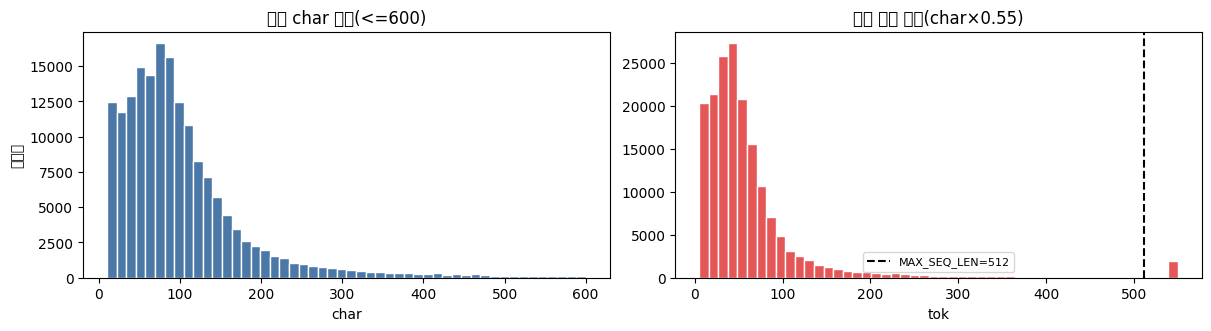

예상 truncation(추정): 1.21% | 배치 수(=64): 2,748

▶ 최장 문장 3개(대개 표 행):
  (1000자) 7 기타 법령, 정관 및 이사회 결의에 의하여 위원회에 부여된 사항을 수행할 의무 감사위원회의 주요활동내역 회 차 개최일자 의 안 내 용 가결여부 감사위원 성용락(출석률:100%) 한철수(출석률:1
  (1000자) (기존) 사내이사1명, 사외이사4명 (변경) 사내이사 1명, 사외이사 2명 사외이사 후보추천위원회 활동 내역 회차 개최일자 의안내용 가결여부 사내이사의 성명 사외이사의 성명 윤영준(출석률:100%)
  (1000자) 선출기준의 주요내용 선출기준의 충족여부 관련 법령 등 - 3명의 이사로 구성 충족(4명) 상법 제415조의2 제2항, 당사 감사위원회 규정 제4조 - 사외이사가 위원의 3분의 2 이상 충족(전원 사
▶ 중앙값 부근 2개:
  • K9 자주포는 세계 최고 수준의 성능과 산악지역부터 평원, 설원, 사막 등 다양한 환경에서 뛰어난 기동성을 인정받으며 세계 8개국 수출에 성공했습니다.
  • 이외에도 Disney+, Amazon Prime Video, Apple TV+ 등 컨텐츠 공급 파트너를 확장하며 시장 변화에 발맞추어 진화하고 있습니다

[해석 가이드]
 • EMB_SIG=(Step2 parquet_sig · 모델 · 문장수). Step2 가 바뀌면 자동 변경 → 자동 재인코딩(캐시 무효화).
 • 추정 토큰은 char×0.55 근사 — 실제는 모델 토크나이저가 결정. MAX_SEQ_LEN 초과분만 잘림(보통 1~2%).
 • truncation 후보가 거의 표/숫자 행이면 정상(ESG 서술 문장은 대개 512토큰 이내).


In [2]:
# ── Step 3.2 · 문장 로드 · explode(문서→문장) · 캐시 시그니처 ─────────────
CLEAN_VERSION = "v2-chunked-kiwi"     # nb07 Step1.1 과 반드시 일치
MODEL_NAME    = "nlpai-lab/KURE-v1"
MAX_SEQ_LEN   = 512                   # 입력 토큰 상한 (문장 char p99≈999 → 한국어 ~tok 500 내외; nb07 와 동일)
BATCH_SIZE    = 64
EMB_DTYPE     = np.float16

df = pd.read_parquet(SENT_PARQUET)
parquet_sig = str(df.attrs.get("sig", "noattr"))   # Step2 시그니처(전처리 바뀌면 자동 변경)

# 문서별 문장배열 → 문장 단위로 풀기 (doc_id = "{stock_code}_{fiscal_year}")
doc_id, stock_code, fiscal_year, sent_idx, sentences = [], [], [], [], []
for r in df.itertuples(index=False):
    sc = str(r.stock_code); fy = int(r.fiscal_year); did = f"{sc}_{fy}"
    for j, s in enumerate(r.sentences):
        doc_id.append(did); stock_code.append(sc); fiscal_year.append(fy)
        sent_idx.append(j); sentences.append(str(s))
doc_id = np.array(doc_id); stock_code = np.array(stock_code)
fiscal_year = np.array(fiscal_year, dtype=np.int16); sent_idx = np.array(sent_idx, dtype=np.int32)
N = len(sentences)
EMB_SIG = hashlib.md5("|".join([parquet_sig, MODEL_NAME, str(N)]).encode()).hexdigest()[:12]
print(f"문서 {df.shape[0]} | 문장 {N:,} | parquet_sig={parquet_sig} | EMB_SIG={EMB_SIG}")

# 캐시 무효화: 기존 npz meta.sig 와 비교 → 일치하면 인코딩 생략
need_encode = True
if EMB_NPZ.exists():
    try:
        meta = json.loads(str(np.load(EMB_NPZ, allow_pickle=True)["meta"]))
        if meta.get("sig") == EMB_SIG and meta.get("n_sentences") == N:
            need_encode = False; print("✅ 기존 npz 재사용 (sig 일치) — 인코딩 생략")
        else:
            print(f"♻ sig 불일치 → 재인코딩 ({meta.get('sig')} ≠ {EMB_SIG})")
    except Exception as e:
        print("기존 npz 메타 읽기 실패 → 재인코딩:", e)
else:
    print("npz 없음 → 신규 인코딩")

# ── ① 시각화: 문장 char 길이 + 추정 토큰 길이 분포 ──
clen = np.array([len(s) for s in sentences]); est_tok = (clen * 0.55).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), constrained_layout=True)
ax[0].hist(clen[clen <= 600], bins=50, color="#4C78A8", edgecolor="white")
ax[0].set_title("문장 char 길이(<=600)"); ax[0].set_xlabel("char"); ax[0].set_ylabel("문장수")
ax[1].hist(est_tok[est_tok <= 600], bins=50, color="#E45756", edgecolor="white")
ax[1].axvline(MAX_SEQ_LEN, color="k", ls="--", label=f"MAX_SEQ_LEN={MAX_SEQ_LEN}")
ax[1].set_title("추정 토큰 길이(char×0.55)"); ax[1].set_xlabel("tok"); ax[1].legend(fontsize=8)
plt.show()
print(f"예상 truncation(추정): {(est_tok > MAX_SEQ_LEN).mean():.2%} | 배치 수(={BATCH_SIZE}): {int(np.ceil(N/BATCH_SIZE)):,}")

# ── ② 샘플: 최장 문장 3개(=truncation 후보) + 중앙값 부근 2개 ──
order = np.argsort(-clen)
print("\n▶ 최장 문장 3개(대개 표 행):")
for i in order[:3]: print(f"  ({clen[i]}자) {sentences[i][:110]}")
print("▶ 중앙값 부근 2개:")
for i in order[N // 2:N // 2 + 2]: print(f"  • {sentences[i][:110]}")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • EMB_SIG=(Step2 parquet_sig · 모델 · 문장수). Step2 가 바뀌면 자동 변경 → 자동 재인코딩(캐시 무효화).")
print(" • 추정 토큰은 char×0.55 근사 — 실제는 모델 토크나이저가 결정. MAX_SEQ_LEN 초과분만 잘림(보통 1~2%).")
print(" • truncation 후보가 거의 표/숫자 행이면 정상(ESG 서술 문장은 대개 512토큰 이내).")


In [ ]:
# ── Step 3.2b · 〔검증 · 로컬 실행 가능〕 실제 토크나이저 truncation 정밀 진단 ──────────
# 목적: Step3.2 의 '추정' truncation(char×0.55) 대신 KURE-v1 **실제 토크나이저**로
#   512토큰을 넘겨 '잘려나가는 꼬리'에 E/S/G 핵심단어가 얼마나 들어있는지 세어, truncation 손실의 안전성을 검증.
# [환경] 임베딩 모델이 아니라 토크나이저만 로드 → 가벼움. 로컬(uv)·Colab 모두 동작.
import re
from transformers import AutoTokenizer

MAX_SEQ_LEN = globals().get("MAX_SEQ_LEN", 512)
MODEL_NAME  = globals().get("MODEL_NAME", "nlpai-lab/KURE-v1")
CONTENT_TOK = MAX_SEQ_LEN - 2          # CLS/SEP(bge-m3=XLM-R: <s>..</s>) 제외한 실제 본문 토큰 한도

# sentences/clen 이 앞 셀(3.2)에 없으면 parquet 에서 복원 (이 셀 단독 실행 대비)
if "sentences" not in globals():
    _df = pd.read_parquet(SENT_PARQUET)
    sentences = [str(s) for r in _df.itertuples(index=False) for s in r.sentences]
if "clen" not in globals():
    clen = np.array([len(s) for s in sentences])
N = len(sentences)

# ESG 핵심단어 = seed_dictionary.csv 의 pattern('|' 분해) — 회귀에 쓴 30개 seed 와 동일 출처
_seed = pd.read_csv(PROJECT / "data" / "raw" / "seed_dictionary.csv")
ESG_KW = {"E": set(), "S": set(), "G": set()}
for _, r in _seed.iterrows():
    for w in str(r["pattern"]).split("|"):
        w = w.strip()
        if w: ESG_KW[r["dimension"]].add(w)
ESG_RE = {d: re.compile("|".join(re.escape(w) for w in sorted(ESG_KW[d], key=len, reverse=True)))
          for d in ESG_KW}

# 토크나이저 로드(가벼움). 토큰 수 자체는 fast/slow 동일 → truncation 판정은 정확.
_tok = AutoTokenizer.from_pretrained(MODEL_NAME)

# 전수 토큰화는 불필요: 토큰 1개는 char ≥1 이므로 char_len < CONTENT_TOK 면 절대 안 잘림. 안전마진 후보만 토큰화.
cand = np.where(clen >= CONTENT_TOK - 60)[0]
trunc_rows = []                                   # (idx, n_tok, boundary_char, char_len, tail_esg_hits)
tail_hits = {"E": 0, "S": 0, "G": 0}; full_hits = {"E": 0, "S": 0, "G": 0}
for i in cand:
    i = int(i)
    enc = _tok(sentences[i], add_special_tokens=False, return_offsets_mapping=True)
    ids = enc["input_ids"]; n_tok = len(ids)
    if n_tok <= CONTENT_TOK:
        continue
    # 잘려나가기 시작하는 첫 토큰(index=CONTENT_TOK)의 char 시작 위치 = 절단 경계
    try:
        boundary = enc["offset_mapping"][CONTENT_TOK][0]
    except Exception:                              # offset 미지원 환경 → 비례 근사
        boundary = int(len(sentences[i]) * CONTENT_TOK / n_tok)
    full = sentences[i]; tail = full[boundary:]
    th = 0
    for d in ESG_KW:
        full_hits[d] += len(ESG_RE[d].findall(full))
        t = len(ESG_RE[d].findall(tail)); tail_hits[d] += t; th += t
    trunc_rows.append((i, n_tok, boundary, len(full), th))

trunc = pd.DataFrame(trunc_rows, columns=["idx", "n_tok", "boundary_char", "char_len", "tail_esg_hits"])
n_trunc = len(trunc); n_tail_kw = int((trunc["tail_esg_hits"] > 0).sum())
tot_tail = sum(tail_hits.values()); tot_full = sum(full_hits.values())
print(f"실제 truncation 문장 : {n_trunc:,}개 = 전체 {N:,}문장의 {n_trunc/N:.2%}   ← Step3.2 추정(~1.21%) 검증")
print(f"  └ 꼬리(>512tok 절단부)에 ESG 단어 ≥1개 있는 문장 : {n_tail_kw:,}개 ({n_tail_kw/max(n_trunc,1):.1%})")
print(f"  └ 잘려나간 ESG 단어 총량 : 꼬리 {tot_tail:,} / 같은 문장 전체 {tot_full:,} = {tot_tail/max(tot_full,1):.1%}")
print("  └ 차원별 꼬리/전체 :", {d: f"{tail_hits[d]}/{full_hits[d]}" for d in ESG_KW})

# ── ① 시각화: (좌) 차원별 전체 vs 절단꼬리 키워드 출현, (우) 절단 경계 char 분포 ──
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True)
dims = list(ESG_KW); x = np.arange(len(dims)); w = 0.38
ax[0].bar(x - w/2, [full_hits[d] for d in dims], w, label="문장 전체", color="#BAB0AC")
ax[0].bar(x + w/2, [tail_hits[d] for d in dims], w, label="잘린 꼬리(>512tok)", color="#E45756")
for k, d in enumerate(dims):
    r = tail_hits[d] / max(full_hits[d], 1)
    ax[0].text(x[k] + w/2, tail_hits[d], f" {r:.0%}", ha="center", va="bottom", fontsize=8, color="#E45756")
ax[0].set_xticks(x); ax[0].set_xticklabels(dims); ax[0].set_ylabel("키워드 출현수(누적)")
ax[0].set_title("잘린 문장 속 ESG 키워드: 전체 vs 절단 꼬리"); ax[0].legend(fontsize=8)
ax[1].hist(trunc["boundary_char"], bins=40, color="#4C78A8", edgecolor="white")
ax[1].set_title("절단 경계 char 위치 분포"); ax[1].set_xlabel("boundary char"); ax[1].set_ylabel("문장수")
plt.show()

# ── ② 샘플: 꼬리에 ESG 단어가 가장 많이 잘려나간 문장 3개(앞=유지 / 뒤=절단) ──
print("\n▶ 꼬리에 ESG 단어가 가장 많이 잘려나간 문장 3개:")
for _, row in trunc.sort_values("tail_esg_hits", ascending=False).head(3).iterrows():
    i = int(row.idx); b = int(row.boundary_char)
    print(f"  idx{i} | {int(row.n_tok)}tok/{int(row.char_len)}자 | 꼬리ESG {int(row.tail_esg_hits)}개")
    print(f"    …유지: {sentences[i][max(0, b-45):b]}")
    print(f"    ✂ 절단: {sentences[i][b:b+135]}")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • 실제 truncation 비율이 Step3.2 추정(~1.21%)과 비슷하면 char×0.55 추정이 타당했음을 확인.")
print(" • 핵심 지표는 '꼬리 ESG 손실률'(꼬리/전체). 낮을수록 임베딩이 놓치는 ESG 단어가 적다 → truncation 안전.")
print(" • 절단 샘플이 대부분 이사회 의결·표(찬성/가결/의안)면 G 단어가 많이 잡혀도 '서술 신호'가 아니라 표 반복 → 손실 무해.")
print("   반대로 E/S 서술문장이 통째로 꼬리에서 잘리면 경계 — 그 경우 문장분할(Step2) 또는 max_seq_len 재검토.")


기존 emb 재사용: (175823, 1024) float16


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51076 (\N{HANGUL SYLLABLE IM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48288 (\N{HANGUL SYLLABLE BE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46377 (\N{HANGUL SYLLABLE DING}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


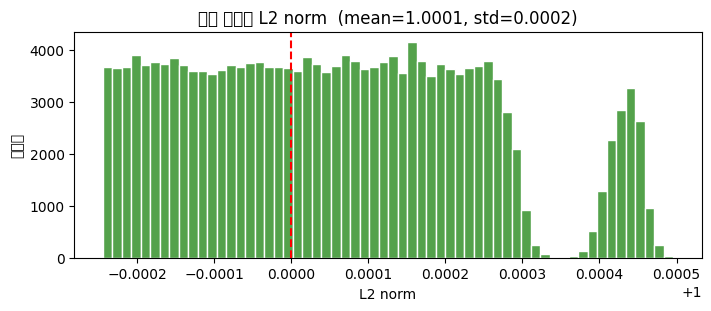

▶ emb[0][:8] = [-0.0548  0.0294 -0.0199  0.0121 -0.0371  0.0173  0.0063  0.0228] | dim 1024
▶ norm≈0(빈/깨진 문장) 개수: 0

[해석 가이드]
 • norm 이 1.0 부근(±0.01)에 몰리면 L2 정규화 정상 → 코사인=내적. fp16 이라 정확히 1.0 은 아님(정상).
 • dim=1024 확인. norm≈0 인 벡터가 있으면 빈/깨진 문장 → 전처리 점검 필요(없어야 정상).
 • T4 기준 175k 문장 인코딩은 대략 수~십수 분. OOM 시 BATCH_SIZE 를 32 로 낮춘다.


In [3]:
# ── Step 3.3 · KURE-v1 로드 · 문장 임베딩 인코딩 (T4 fp16) ───────────────
from sentence_transformers import SentenceTransformer

if need_encode:
    t0 = time.time()
    model = SentenceTransformer(MODEL_NAME, device=dev)
    model.max_seq_length = MAX_SEQ_LEN
    if dev == "cuda": model = model.half()      # fp16 추론 (T4 속도/메모리)
    print(f"모델 로드 {time.time()-t0:.0f}s | dim={model.get_sentence_embedding_dimension()} | max_seq={model.max_seq_length}")
    t0 = time.time()
    emb = model.encode(sentences, batch_size=BATCH_SIZE, normalize_embeddings=True,
                       convert_to_numpy=True, show_progress_bar=True)
    emb = emb.astype(EMB_DTYPE)
    print(f"인코딩 완료 {time.time()-t0:.0f}s | shape={emb.shape} | dtype={emb.dtype}")
else:
    emb = np.load(EMB_NPZ, allow_pickle=True)["emb"]
    print("기존 emb 재사용:", emb.shape, emb.dtype)

assert emb.shape[0] == N and emb.shape[1] == 1024, f"shape 이상: {emb.shape}"

# ── ① 시각화: 임베딩 L2 norm 분포 (정규화 확인) ──
norms = np.linalg.norm(emb.astype(np.float32), axis=1)
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.hist(norms, bins=60, color="#54A24B", edgecolor="white"); ax.axvline(1.0, color="r", ls="--")
ax.set_title(f"문장 임베딩 L2 norm  (mean={norms.mean():.4f}, std={norms.std():.4f})")
ax.set_xlabel("L2 norm"); ax.set_ylabel("문장수"); plt.show()

# ── ② 샘플: 임베딩 벡터 일부 + 0벡터 점검 ──
print("▶ emb[0][:8] =", np.round(emb[0][:8].astype(float), 4), "| dim", emb.shape[1])
print("▶ norm≈0(빈/깨진 문장) 개수:", int((norms < 0.5).sum()))

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • norm 이 1.0 부근(±0.01)에 몰리면 L2 정규화 정상 → 코사인=내적. fp16 이라 정확히 1.0 은 아님(정상).")
print(" • dim=1024 확인. norm≈0 인 벡터가 있으면 빈/깨진 문장 → 전처리 점검 필요(없어야 정상).")
print(" • T4 기준 175k 문장 인코딩은 대략 수~십수 분. OOM 시 BATCH_SIZE 를 32 로 낮춘다.")


재로드 OK | meta = {'sig': '402efddb86ca', 'parquet_sig': '462a9a3b4945', 'model': 'nlpai-lab/KURE-v1', 'dim': 1024, 'n_docs': 381, 'n_sentences': 175823, 'clean_version': 'v2-chunked-kiwi', 'max_seq_len': 512, 'dtype': 'float16', 'normalized': True, 'created_at': '2026-06-01 01:53:42'}


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49933 (\N{HANGUL SYLLABLE SSANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53076 (\N{HANGUL SYLLABLE KO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

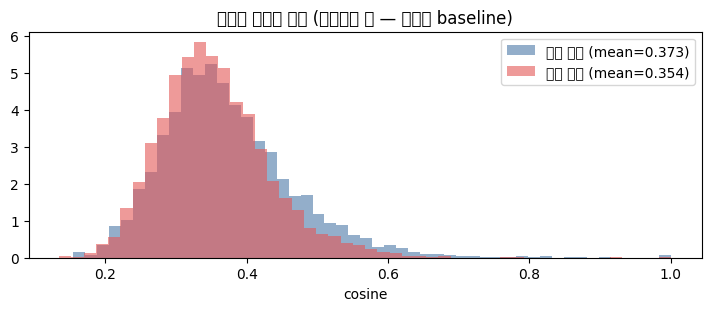

같은문서 mean=0.373 vs 다른문서 mean=0.354  (차 +0.018)

▶ 기준 문장: 동화크립톤 기업가정신 제일호 창업벤처전문 사모투자합자회사(1) 개요 종속회사 동화크립톤 기업가정신 제일호 창업벤처전문 사모투자합자회사는 자본시장과 금융투자업에 관한 법률(이하 자본
  (1.000) 동화크립톤 기업가정신 제일호 창업벤처전문 사모투자합자회사(1) 개요 종속회사 동화크립톤 기업가정신 제일호 창업벤처전문 사모투자합자회사는 자본시장과 금융투자업에 관한 법률(이하 자본
  (1.000) 동화크립톤 기업가정신 제일호 창업벤처전문 사모투자합자회사(1) 개요 종속회사 동화크립톤 기업가정신 제일호 창업벤처전문 사모투자합자회사는 자본시장과 금융투자업에 관한 법률(이하 자본
  (0.674) 기업명 소재지 결산일 업종 지분율(%) 당기말 전기말 동화크립톤 기업가정신제일호 창업벤처전문사모투자합자회사 대한민국 12월 31일 사모투자전문회사 당기말 현재 종속기업의 요약 재무

[해석 가이드]
 • '같은 문서' mean 이 '다른 문서' mean 보다 높으면(차 +) 임베딩이 문맥/주제를 담음(정상).
 • '다른 문서' mean 이 0이 아니라 ~0.3 부근이면 사전학습 임베딩의 이방성(정상) — Step4 화이트닝이 이 baseline 을 낮춘다(§5.1).
 • 기준 ESG 문장의 top 유사 문장이 같은 주제면 정상. 표/숫자 행이 올라오면 표잔재 영향(G2 에서 점검).
 • 이 npz 를 data/processed/ 에 두면 nb07 Step4(화이트닝)가 읽는다. (Colab+Drive 면 이미 그 위치)


In [4]:
# ── Step 3.4 · 저장(npz) · 재로드 검증 · 코사인 sanity ──────────────────
meta = dict(sig=EMB_SIG, parquet_sig=parquet_sig, model=MODEL_NAME, dim=int(emb.shape[1]),
            n_docs=int(df.shape[0]), n_sentences=int(N), clean_version=CLEAN_VERSION,
            max_seq_len=MAX_SEQ_LEN, dtype=str(emb.dtype), normalized=True,
            created_at=time.strftime("%Y-%m-%d %H:%M:%S"))

if need_encode:
    EMB_NPZ.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(EMB_NPZ, emb=emb, doc_id=doc_id, stock_code=stock_code,
                        fiscal_year=fiscal_year, sent_idx=sent_idx,
                        meta=json.dumps(meta, ensure_ascii=False))
    print(f"저장: {EMB_NPZ}  ({EMB_NPZ.stat().st_size/1e6:.0f} MB)")

# 재로드 검증
z = np.load(EMB_NPZ, allow_pickle=True); m = json.loads(str(z["meta"]))
assert z["emb"].shape == (N, 1024), f"shape 불일치 {z['emb'].shape}"
assert z["doc_id"].shape[0] == N and z["sent_idx"].shape[0] == N, "인덱스 길이 불일치"
assert m["sig"] == EMB_SIG, "저장된 sig 불일치"
print("재로드 OK | meta =", m)

E = z["emb"].astype(np.float32); did = z["doc_id"]
rng = np.random.default_rng(0)

# ── ① 시각화: 같은 문서 vs 다른 문서 문장쌍 코사인 분포 (화이트닝 前 baseline) ──
# [주의] 무작위 두 인덱스로는 같은-문서 쌍이 거의 안 걸린다(P≈0.3%, 4000쌍 중 ~10개).
#        → 같은-문서는 '문서별 그룹에서 직접' 표집해야 분포가 제대로 보인다.
from collections import defaultdict
_grp = defaultdict(list)
for _i, _d in enumerate(did):
    _grp[_d].append(_i)
_grp = {d: np.array(ix) for d, ix in _grp.items() if len(ix) >= 2}
def cos_same(k=5000):
    out = np.empty(k, dtype=np.float32); keys = list(_grp.keys())
    for t, d in enumerate(rng.choice(keys, size=k)):
        a, b = rng.choice(_grp[d], 2, replace=False); out[t] = float(E[a] @ E[b])
    return out
def cos_diff(k=5000):
    idx = rng.integers(0, N, size=(k, 2)); mask = did[idx[:, 0]] != did[idx[:, 1]]
    sel = idx[mask]; return (E[sel[:, 0]] * E[sel[:, 1]]).sum(1)
cs, cd = cos_same(), cos_diff()
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.hist(cs, bins=50, alpha=.6, density=True, color="#4C78A8", label=f"같은 문서 (mean={cs.mean():.3f})")
ax.hist(cd, bins=50, alpha=.6, density=True, color="#E45756", label=f"다른 문서 (mean={cd.mean():.3f})")
ax.set_title("문장쌍 코사인 분포 (화이트닝 前 — 이방성 baseline)")
ax.set_xlabel("cosine"); ax.legend(); plt.show()
print(f"같은문서 mean={cs.mean():.3f} vs 다른문서 mean={cd.mean():.3f}  (차 {cs.mean()-cd.mean():+.3f})")

# ── ② 샘플: ESG성 문장 기준 top-3 유사 문장 ──
kw = ["온실가스", "탄소", "지배구조", "이사회", "안전보건", "재생에너지", "지속가능"]
seed = next((i for i, s in enumerate(sentences) if any(k in s for k in kw)), 0)
sims = E @ E[seed]; top = np.argsort(-sims)[1:4]
print(f"\n▶ 기준 문장: {sentences[seed][:100]}")
for i in top: print(f"  ({sims[i]:.3f}) {sentences[i][:100]}")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • '같은 문서' mean 이 '다른 문서' mean 보다 높으면(차 +) 임베딩이 문맥/주제를 담음(정상).")
print(" • '다른 문서' mean 이 0이 아니라 ~0.3 부근이면 사전학습 임베딩의 이방성(정상) — Step4 화이트닝이 이 baseline 을 낮춘다(§5.1).")
print(" • 기준 ESG 문장의 top 유사 문장이 같은 주제면 정상. 표/숫자 행이 올라오면 표잔재 영향(G2 에서 점검).")
print(" • 이 npz 를 data/processed/ 에 두면 nb07 Step4(화이트닝)가 읽는다. (Colab+Drive 면 이미 그 위치)")

## 🚦 Step 3 — 임베딩 (재)생성 판정

| # | PASS 기준 | 확인 위치 |
|---|---|---|
| 1 | shape = **(175823, 1024)** | 3.3 / 3.4 assert |
| 2 | L2 norm ≈ **1.0**(±0.01), norm≈0 문장 0개 | 3.3 히스토그램 |
| 3 | dim = **1024** | 3.3 |
| 4 | npz `meta.sig == EMB_SIG`(`402efddb86ca` 예상) · `n_sentences==175823` | 3.4 |
| 5 | 같은 문서 코사인 > 다른 문서 코사인 | 3.4 분포 |

위 5항목 충족 시 **PASS**. (Step 3 자체엔 별도 Gate 없음 — 정식 게이트는 G2 풀링부터.)

### 다음 단계
- **Step 4 — 화이트닝**(nb07 에 이어서): 평균제거 + 표준화 → ABTT(상위 주성분 제거) 또는 ZCA.
  비지도 피처용 파라미터는 **전체 코퍼스**에서 적합(라벨 미사용 → 순환성 없음, `03_features.md` §5.1).
- 산출 `07_v2_sentence_emb.npz` 를 `data/processed/` 로 확보(Drive 사용 시 이미 위치).

> **REVIEW REQUIRED** — Colab(T4)에서 본 노트북 실행 → npz(약 350MB) 생성 확인되면 nb07 Step 4(화이트닝) 진행.

## Step 4 — 화이트닝 (이방성 완화) · ABTT vs ZCA 비교 〔Colab · §5.1〕

> 상세 [`plan/03_features.md`](../plan/03_features.md) §5.1

Step 3 코사인에서 본 **이방성**(무관한 문장도 cos≈0.33)을 완화한다. **평균제거 + 표준화** 후 두 방식을 비교한다.

| 방식 | 내용 | 성격 |
|---|---|---|
| **ABTT** | 상위 `d≈D/100`(≈10) 주성분 제거 | 가벼움·해석 쉬움, 판별 gap 보존 경향 |
| **ZCA** | 공분산 화이트닝 `W=Σ^{-1/2}` (cov→I) | 완전 등방화, gap 더 줄 수 있음 |

- **순환성 방어**: 비지도 피처용 화이트닝은 **전체 코퍼스**에서 적합(라벨 미사용 → 순환성 없음). 지도 프로브용은 나중에 **CV 학습폴드 내**에서만(§5.4).
- **판단 기준**: `다른문서 mean`(이방성) **↓** + `gap`(같음−다름, 판별력) **유지/↑**.
- 화이트닝 파라미터는 `data/processed/07_v2_whiten.npz`(작음)로 저장 → **채택분을 Step 6 풀링(G2)에 적용**.
- ⚠ 이 셀은 3.4 까지 실행된 세션에서 이어 실행(메모리의 `E`/`did`/`_grp` 재사용). 새 세션이면 위에서부터 실행(npz 캐시로 인코딩은 생략됨).

In [5]:
  !apt-get -qq -y install fonts-nanum > /dev/null
  import matplotlib.font_manager as fm
  from matplotlib import rcParams
  for _fp in fm.findSystemFonts(['/usr/share/fonts/truetype/nanum']):
      fm.fontManager.addfont(_fp)          # 캐시 재빌드 없이 즉시 등록
  rcParams['font.family'] = 'NanumGothic'
  rcParams['axes.unicode_minus'] = False   # 음수 부호 깨짐 방지
  print('폰트:', rcParams['font.family'])

폰트: ['NanumGothic']


▶ 화이트닝 변형 비교:
        변형  같은문서 mean  다른문서 mean(이방성)  gap(같음-다름)
  raw(정규화)      0.373           0.351       0.022
ABTT(d=10)      0.021           0.001       0.020
       ZCA      0.012           0.000       0.012


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumGothic.
  fig.canvas.print_figure(bytes_io, **kw)


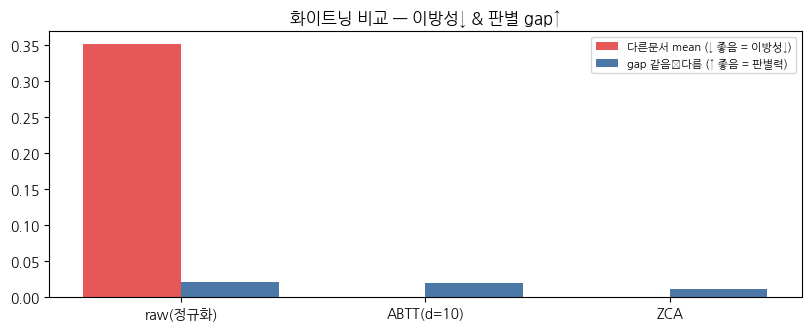


▶ 같은 문서(000020_2022) 문장 2개의 코사인 변화:
   A: 사업의 내용 사업의 개요 일반적인 사항지배기업인 연결실체는 제공하는 재화나 용역에 근거하여 영업부문을 구분하고 각 부문의 재무정보를 내부관리 목
   B: 영위하는 영업부문 중 기타금융업의 경우 중요성의 관점에서 비중이 크지 않습니다
   raw(정규화)     cos(A,B) = 0.561
   ABTT(d=10)   cos(A,B) = 0.106
   ZCA          cos(A,B) = 0.065

화이트닝 파라미터 저장: 07_v2_whiten.npz  (3.9 MB)

[해석 가이드]
 • 목표: '다른문서 mean'(이방성)을 0 근처로 낮추되 'gap'(같음−다름, 판별력)은 유지/키운다.
 • 보통 ZCA 는 cov→I 로 완전 등방화(다른문서≈0) 하지만 gap 을 더 줄일 수 있고,
   ABTT 는 상위 few 주성분만 제거 → 이방성은 줄이며 gap 을 더 잘 보존하는 편(데이터마다 다름).
 • 위 표/그림으로 ABTT vs ZCA 중 채택을 결정 → Step 5 앵커(02_anchors.md) 후 Step 6 풀링(G2)에서 적용.
   ▶ REVIEW REQUIRED: 어느 화이트닝을 쓸지 사용자 선택 필요.


In [6]:
# ── Step 4.1 · 화이트닝 (평균제거+표준화 → ABTT / ZCA) · 비교 ──────────────
# [순환성] 비지도 피처용 화이트닝은 전체 코퍼스에서 적합(라벨 미사용 → 순환성 없음, §5.1).
#          지도 프로브용 화이트닝은 나중에 CV 학습폴드 내에서만(§5.4).
# 입력: 3.4 에서 만든 E(=z['emb'] fp32, L2정규화), did, sentences, _grp, rng 재사용.
X = E                                          # (N,1024) raw L2-normalized
mu  = X.mean(0, keepdims=True)
Xc  = X - mu                                   # 평균제거
std = Xc.std(0, keepdims=True) + 1e-8
Xs  = Xc / std                                 # 표준화(per-dim z)

def eig_cov(M):                                # M은 이미 중심화됨 → 공분산 고유분해(내림차순)
    C = ((M.T @ M) / (M.shape[0] - 1)).astype(np.float64)
    w, V = np.linalg.eigh(C); o = np.argsort(-w)
    return w[o], V[:, o]

D = X.shape[1]; d_abtt = max(1, round(D / 100))            # ≈10 (Mu & Viswanath 권장 D/100)
# (A) ABTT: 표준화 데이터에서 상위 d 주성분 제거
w_s, V_s = eig_cov(Xs); top = V_s[:, :d_abtt].astype(np.float32)
X_abtt = Xs - (Xs @ top) @ top.T
# (B) ZCA: 중심화 데이터 화이트닝 W = Σ^{-1/2} (대칭, cov→I)
w_c, V_c = eig_cov(Xc); eps = 1e-5
W_zca = ((V_c * (1.0 / np.sqrt(w_c + eps))) @ V_c.T).astype(np.float32)
X_zca = Xc @ W_zca

def l2n(A):
    n = np.linalg.norm(A, axis=1, keepdims=True); n[n == 0] = 1; return A / n
variants = {"raw(정규화)": l2n(X), f"ABTT(d={d_abtt})": l2n(X_abtt), "ZCA": l2n(X_zca)}
del Xc, Xs, X_abtt, X_zca                       # 메모리 정리(정규화본만 유지)

# ── ① 시각화: 변형별 같은/다른 문서 코사인 baseline 비교 ──
keys = list(_grp.keys())
def diag(M, k=4000):
    same = np.empty(k, dtype=np.float32)
    for t, dk in enumerate(rng.choice(keys, k)):
        a, b = rng.choice(_grp[dk], 2, replace=False); same[t] = M[a] @ M[b]
    idx = rng.integers(0, N, (k, 2)); mk = did[idx[:, 0]] != did[idx[:, 1]]; sel = idx[mk]
    diff = (M[sel[:, 0]] * M[sel[:, 1]]).sum(1)
    return float(same.mean()), float(diff.mean())
rows = [(name, *diag(M)) for name, M in variants.items()]
tab = pd.DataFrame([(n, s, d, s - d) for n, s, d in rows],
                   columns=["변형", "같은문서 mean", "다른문서 mean(이방성)", "gap(같음-다름)"]).round(3)
print("▶ 화이트닝 변형 비교:"); print(tab.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.2), constrained_layout=True)
xs = np.arange(len(rows)); wb = 0.4
ax.bar(xs - wb/2, [r[2] for r in rows], wb, label="다른문서 mean (↓ 좋음 = 이방성↓)", color="#E45756")
ax.bar(xs + wb/2, [r[1] - r[2] for r in rows], wb, label="gap 같음−다름 (↑ 좋음 = 판별력)", color="#4C78A8")
ax.set_xticks(xs); ax.set_xticklabels([r[0] for r in rows]); ax.axhline(0, color="k", lw=.5)
ax.set_title("화이트닝 비교 — 이방성↓ & 판별 gap↑"); ax.legend(fontsize=8); plt.show()

# ── ② 샘플: 같은 문서 2개 문장의 코사인 변화(raw→ABTT→ZCA) ──
d0 = keys[0]; a, b = _grp[d0][:2]
print(f"\n▶ 같은 문서({d0}) 문장 2개의 코사인 변화:")
print(f"   A: {sentences[a][:80]}")
print(f"   B: {sentences[b][:80]}")
for name, M in variants.items():
    print(f"   {name:12s} cos(A,B) = {float(M[a] @ M[b]):.3f}")

# ── 화이트닝 파라미터 저장(작음) — 채택분은 Step6 풀링에 적용 ──
WHITEN_NPZ = DATA / "07_v2_whiten.npz"
np.savez_compressed(WHITEN_NPZ, mu=mu.astype(np.float32), std=std.astype(np.float32),
                    abtt_top=top, zca_W=W_zca, d_abtt=np.array(d_abtt),
                    parquet_sig=np.array(parquet_sig), emb_sig=np.array(EMB_SIG))
print(f"\n화이트닝 파라미터 저장: {WHITEN_NPZ.name}  ({WHITEN_NPZ.stat().st_size/1e6:.1f} MB)")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • 목표: '다른문서 mean'(이방성)을 0 근처로 낮추되 'gap'(같음−다름, 판별력)은 유지/키운다.")
print(" • 보통 ZCA 는 cov→I 로 완전 등방화(다른문서≈0) 하지만 gap 을 더 줄일 수 있고,")
print("   ABTT 는 상위 few 주성분만 제거 → 이방성은 줄이며 gap 을 더 잘 보존하는 편(데이터마다 다름).")
print(" • 위 표/그림으로 ABTT vs ZCA 중 채택을 결정 → Step 5 앵커(02_anchors.md) 후 Step 6 풀링(G2)에서 적용.")
print("   ▶ REVIEW REQUIRED: 어느 화이트닝을 쓸지 사용자 선택 필요.")

앵커 문장 수: 27 | 차원별 {'E': 11, 'S': 9, 'G': 7} | 하위차원 22


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/16.9k [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

모델 로드(앵커 인코딩용)


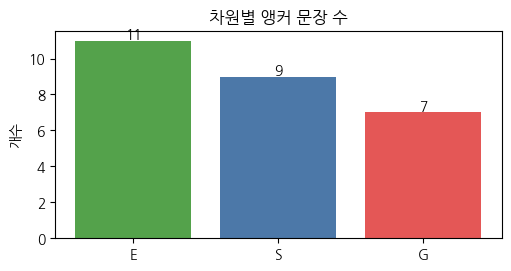


▶.앵커 샘플:
  [E] E1 환경경영목표 → 기업은 환경경영 목표와 추진체계를 수립하고 환경경영시스템을 운영한다.
  [S] S1 노동 → 기업은 신규 채용과 정규직 비율, 고용 안정을 관리한다.
  [G] G1 이사회 구성 → 기업은 이사회 내 ESG 안건을 상정하고 사외이사 비율과 전문성을 강화한다.

[해석 가이드]
 • 앵커는 02_anchors.md(선생님 편집)에서 옴 — 수정하려면 그 파일을 고치고 이 셀부터 재실행.
 • 앵커도 문장과 '동일한' ABTT 화이트닝을 거쳐야 같은 공간에서 코사인 비교가 정당하다.
 • 다음 5.2 에서 차원 간 분리(대각지배)·하위 응집·최근접 문장으로 앵커 품질을 검증한다.


In [7]:
# ── Step 5.1 · 앵커 정의 · 인코딩 · ABTT 화이트닝 ───────────────────────────
# plan/02_anchors.md (선생님 편집)의 하위차원 기준문장. 회귀 피처는 E/S/G 3개, 하위차원=진단용.
ANCHORS = {
 "E": {
  "E1 환경경영목표": ["기업은 환경경영 목표와 추진체계를 수립하고 환경경영시스템을 운영한다."],
  "E2 원부자재": ["기업은 원부자재 사용량을 관리하고 재생 원부자재 사용 비율을 높인다."],
  "E3 온실가스·에너지": ["기업은 온실가스 배출량(Scope 1·2·3)을 측정·검증하고 감축 목표를 추진한다.",
                  "기업은 에너지 사용량을 관리하고 재생에너지 사용 비율을 확대한다."],
  "E4 용수·폐기물": ["기업은 용수 사용량과 재사용 비율을 관리한다.",
                "기업은 폐기물 배출을 줄이고 재활용 비율을 높인다."],
  "E5 오염물질": ["기업은 대기오염물질과 수질오염물질 배출을 저감한다."],
  "E6 환경 법규·라벨링": ["기업은 환경 법규를 준수하고 친환경 인증 제품·서비스 비율을 확대한다."],
  "E7 기후변화대응": ["기업은 기후변화 거버넌스를 갖추고 물리적·전환 리스크를 식별·대응한다.",
                "기업은 온실가스 배출량 감축을 선언하고 중장기 기후 목표를 공시한다."],
  "E8 생물다양성": ["기업은 자연자본을 식별하고 생물다양성 보존과 산림보호 활동을 추진한다."],
 },
 "S": {
  "S1 노동": ["기업은 신규 채용과 정규직 비율, 고용 안정을 관리한다.",
           "기업은 교육훈련과 복리후생을 확대하고 결사의 자유를 보장한다."],
  "S2 다양성·양성평등": ["기업은 여성 구성원 비율과 여성 급여 수준을 개선하고 장애인 고용을 확대한다."],
  "S3 산업안전": ["기업은 안전보건 추진체계를 운영하고 산업재해와 중대재해를 예방한다."],
  "S4 인권": ["기업은 인권정책을 수립하고 인권 리스크를 평가·관리한다."],
  "S5 동반성장·공급망": ["기업은 협력사 ESG 경영을 지원하고 공급망의 사회적 책임을 점검한다."],
  "S6 지역사회": ["기업은 전략적 사회공헌과 구성원 봉사참여를 추진한다."],
  "S7 정보보호": ["기업은 정보보호 시스템을 구축하고 개인정보 침해를 예방·구제한다."],
  "S8 사회 법규": ["기업은 사회 관련 법규를 준수하고 소비자·제품 책임을 이행한다."],
 },
 "G": {
  "G1 이사회 구성": ["기업은 이사회 내 ESG 안건을 상정하고 사외이사 비율과 전문성을 강화한다.",
               "기업은 대표이사와 이사회 의장을 분리하고 이사회의 성별 다양성을 확대한다."],
  "G2 이사회 활동": ["기업은 이사 출석률을 관리하고 이사회 산하 위원회를 통해 안건을 심의한다."],
  "G3 주주권리": ["기업은 주주총회 운영과 의결권 행사를 보장하고 배당정책을 수립·이행한다."],
  "G4 윤리경영": ["기업은 윤리규범을 운영하고 위반사항을 공시하며 부패를 방지한다."],
  "G5 감사기구": ["기업은 내부감사부서를 설치하고 감사기구의 회계·재무 전문성을 확보한다."],
  "G6 지배구조 법규": ["기업은 지배구조 관련 법규를 준수하고 경영 정보를 투명하게 공시한다."],
 },
}
anchor_texts, anchor_dim, anchor_sub = [], [], []
for dim, subs in ANCHORS.items():
    for sub, sents in subs.items():
        for s in sents:
            anchor_texts.append(s); anchor_dim.append(dim); anchor_sub.append(sub)
anchor_dim = np.array(anchor_dim); anchor_sub = np.array(anchor_sub); n_anc = len(anchor_texts)
print("앵커 문장 수:", n_anc, "| 차원별", {d: int((anchor_dim == d).sum()) for d in ["E","S","G"]},
      "| 하위차원", sum(len(v) for v in ANCHORS.values()))

# 모델 보장(캐시 재사용 세션이면 3.3 에서 model 미생성)
try:
    model
except NameError:
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer(MODEL_NAME, device=dev); model.max_seq_length = MAX_SEQ_LEN
    if dev == "cuda": model = model.half()
    print("모델 로드(앵커 인코딩용)")

A_raw = model.encode(anchor_texts, batch_size=BATCH_SIZE, normalize_embeddings=True,
                     convert_to_numpy=True).astype(np.float32)

# ABTT 화이트닝 (문장과 '동일' 변환) — 파라미터는 07_v2_whiten.npz 에서 로드
wz = np.load(WHITEN_NPZ, allow_pickle=True)
mu_w, std_w, top_w = wz["mu"], wz["std"], wz["abtt_top"]
def _l2n(Mx):
    n = np.linalg.norm(Mx, axis=1, keepdims=True); n[n == 0] = 1; return Mx / n
def whiten_abtt(Xin):
    Xc = Xin - mu_w; Xs = Xc / std_w
    return _l2n(Xs - (Xs @ top_w) @ top_w.T)
A = whiten_abtt(A_raw)                       # (n_anc, 1024) 화이트닝 앵커

# ── ① 시각화: 차원별 앵커 수 ──
fig, ax = plt.subplots(figsize=(5, 2.6), constrained_layout=True)
cnt = [int((anchor_dim == d).sum()) for d in ["E","S","G"]]
ax.bar(["E","S","G"], cnt, color=["#54A24B","#4C78A8","#E45756"])
for i, c in enumerate(cnt): ax.text(i, c + 0.1, str(c), ha="center")
ax.set_title("차원별 앵커 문장 수"); ax.set_ylabel("개수"); plt.show()

# ── ② 샘플: 차원별 앵커 1개씩 ──
print("\n▶.앵커 샘플:")
for d in ["E","S","G"]:
    i = int(np.where(anchor_dim == d)[0][0]); print(f"  [{d}] {anchor_sub[i]} → {anchor_texts[i]}")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • 앵커는 02_anchors.md(선생님 편집)에서 옴 — 수정하려면 그 파일을 고치고 이 셀부터 재실행.")
print(" • 앵커도 문장과 '동일한' ABTT 화이트닝을 거쳐야 같은 공간에서 코사인 비교가 정당하다.")
print(" • 다음 5.2 에서 차원 간 분리(대각지배)·하위 응집·최근접 문장으로 앵커 품질을 검증한다.")

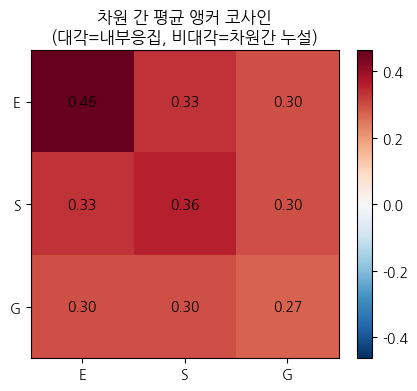

대각지배(각 차원 내부응집 > 타차원): △ 일부 차원 분리 약함

▶ 하위차원 내부 응집(앵커 2개 코사인):
   E3 온실가스·에너지          cos=+0.434
   E4 용수·폐기물            cos=+0.559
   E7 기후변화대응            cos=+0.477
   S1 노동                cos=+0.376
   G1 이사회 구성            cos=+0.401

▶ 앵커별 최근접 실제 문장(top-2):
  [E] E3 온실가스·에너지: 기업은 온실가스 배출량(Scope 1·2·3)을 측정·검증하고 감축 목표를 추진한다.
      (0.520) 2023년 Scope3 탄소배출량 측정을 보완하고, 중장기 감축 목표를 수립할 계획입니다
      (0.477) Scope 3 배출량의 경우, 2030년까지 2021년 대비 17% 감축을 중기 목표로 수립하였습니다
  [S] S3 산업안전: 기업은 안전보건 추진체계를 운영하고 산업재해와 중대재해를 예방한다.
      (0.529) 안전보건관리체계이행 및 점검 정기 산업안전 보건교육- 안전보건 Check List 점검 실시 중대재해 예방을 위한 내부 규정 및 관련 법령을적절히 준수하고 있음
      (0.520) 산업안전보건정책 사업주 또는 경영책임자 등이 안전 및 보건 조치 의무를 위반하여 인명 피해를 동반하는 중대재해가 발생할 경우 사업주 또는 경영책임자, 법인 등에 
  [G] G1 이사회 구성: 기업은 이사회 내 ESG 안건을 상정하고 사외이사 비율과 전문성을 강화한다.
      (0.481) 특히, 환경 관련 주요 사안들에 대해 이사회와 이사회 산하 ESG위원회에서 주기적으로 논의하고 있습니다
      (0.481) 특히, 환경 관련 주요 사안들에 대해 이사회와 이사회 산하 ESG위원회에서 주기적으로 논의하고 있습니다

[해석 가이드]
 • 히트맵 대각(내부응집)이 비대각(차원간)보다 크면 앵커가 차원을 잘 가른다 → G3(판별타당도) 유리

In [8]:
# ── Step 5.2 · 앵커 품질 검증 (차원분리 · 하위응집 · 최근접 문장) ────────────
dims = ["E", "S", "G"]
M = np.zeros((3, 3))
for i, di in enumerate(dims):
    for j, dj in enumerate(dims):
        Ai, Aj = A[anchor_dim == di], A[anchor_dim == dj]
        if i == j:
            iu = np.triu_indices(len(Ai), 1)
            M[i, j] = (Ai @ Ai.T)[iu].mean() if len(iu[0]) else 1.0
        else:
            M[i, j] = (Ai @ Aj.T).mean()

# ── ① 시각화: 3×3 차원 간 평균 앵커 코사인 히트맵 (대각지배 기대) ──
fig, ax = plt.subplots(figsize=(4.4, 3.8), constrained_layout=True)
vlim = float(np.abs(M).max()); im = ax.imshow(M, cmap="RdBu_r", vmin=-vlim, vmax=vlim)
ax.set_xticks(range(3)); ax.set_xticklabels(dims); ax.set_yticks(range(3)); ax.set_yticklabels(dims)
for i in range(3):
    for j in range(3): ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center")
ax.set_title("차원 간 평균 앵커 코사인\n(대각=내부응집, 비대각=차원간 누설)")
fig.colorbar(im, fraction=0.046); plt.show()
diag_ok = all(M[i, i] > max(M[i, j] for j in range(3) if j != i) for i in range(3))
print("대각지배(각 차원 내부응집 > 타차원):", "○ 양호" if diag_ok else "△ 일부 차원 분리 약함")

# 하위차원 내부 응집(앵커 2개 이상인 경우의 쌍 코사인)
print("\n▶ 하위차원 내부 응집(앵커 2개 코사인):")
for d in dims:
    for sub, sents in ANCHORS[d].items():
        if len(sents) >= 2:
            idx = [anchor_texts.index(s) for s in sents]
            print(f"   {sub:20s} cos={float(A[idx[0]] @ A[idx[1]]):+.3f}")

# ── ② 샘플: 차원별 대표 앵커의 최근접 실제 문장 top-2 ──
try:
    del variants            # Step4 비교본 메모리 정리
except NameError:
    pass
S_w = whiten_abtt(E)        # 화이트닝 문장 임베딩 (Step6 풀링에서도 재사용)
print("\n▶ 앵커별 최근접 실제 문장(top-2):")
for d, sub_key in [("E", "E3"), ("S", "S3"), ("G", "G1")]:
    k = int([i for i, s in enumerate(anchor_sub) if s.startswith(sub_key)][0])
    sims = S_w @ A[k]; tt = np.argsort(-sims)[:2]
    print(f"  [{d}] {anchor_sub[k]}: {anchor_texts[k]}")
    for t in tt: print(f"      ({sims[t]:.3f}) {sentences[t][:90]}")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • 히트맵 대각(내부응집)이 비대각(차원간)보다 크면 앵커가 차원을 잘 가른다 → G3(판별타당도) 유리.")
print(" • 최근접 문장이 그 차원 주제(E=환경 / S=안전·노동 / G=이사회·지배구조)면 앵커가 제대로 '당긴다'.")
print(" • 비대각이 대각만큼 크거나 최근접 문장이 엉뚱하면 → 02_anchors.md 에서 해당 앵커 교체 후 5.1~5.2 재실행.")
print("   ▶ REVIEW REQUIRED: 앵커 품질 확인 →(필요시 앵커 수정)→ Step 6 풀링(문장↔앵커 max/mean, G2).")

등급↔분량 상관 ρ(grade, report_len): {'E': np.float64(0.628), 'S': np.float64(0.603), 'G': np.float64(0.577)}

▶ 신호 own-grade ρ:
dim              E      G      S
pool                            
docmean      0.139 -0.209  0.094
max          0.397  0.179  0.300
quant0.9     0.172 -0.159  0.167
quant0.95    0.195 -0.179  0.152
softmax0.05  0.306 -0.028  0.201
softmax0.1   0.264 -0.155  0.178
topk10       0.494  0.275  0.460
topk20       0.537  0.356  0.497
topk5        0.467  0.219  0.417
topp0.02     0.277 -0.123  0.211
topp0.05     0.253 -0.159  0.186
topp0.1      0.245 -0.175  0.170

▶ 부분 ρ (분량 통제=순수신호):
dim              E      G      S
pool                            
docmean      0.003 -0.053  0.053
max          0.169  0.052  0.026
quant0.9     0.084  0.028  0.117
quant0.95    0.071  0.021  0.102
softmax0.05  0.168  0.032  0.058
softmax0.1   0.149 -0.010  0.104
topk10       0.165  0.008  0.093
topk20       0.166  0.039  0.088
topk5        0.171 -0.012  0.091
topp0.02     0.148 -0.020  0.0

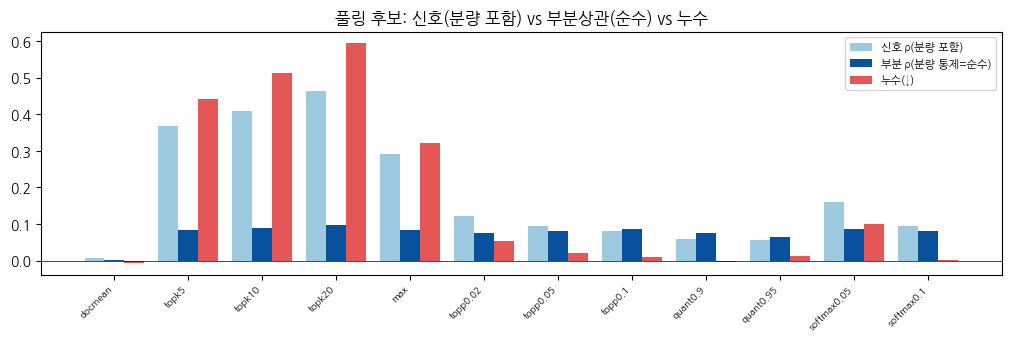


▶ 최장 문서 005490_2024 (문장 2219개) E 점수 풀링값:
   docmean    = 0.086
   topk10     = 0.421
   max        = 0.432
   quant0.9   = 0.182
   topp0.05   = 0.304

[해석 가이드]
 • 핵심 비교: '신호 ρ'(파랑 연) vs '부분 ρ'(파랑 진) — 둘 차이가 크면 그 신호는 분량 착시.
 • 부분 ρ = report_len 통제 후 '순수 차원신호'. 이게 0 근처면 그 차원은 언어로 등급을 못 가른다(정직한 null).
 • 등급↔분량 ρ 이 양(+)이면 '긴 보고서=좋은 등급' 교란 존재 → top-k 의 높은 신호는 대부분 이 교란.
 • 다음 6.2: 부분 ρ(순수신호) 기준으로 풀링 채택 + G2(누수 감소) 판정.


In [9]:
# ── Step 6.1 · 문장→차원 유사도 · 풀링 후보 · 신호/누수/부분상관 ──────────────
from scipy.stats import spearmanr
GRADE_MAP = {"S": 6, "A+": 5, "A": 4, "B+": 3, "B": 2, "C": 1, "D": 0}

# (1) 문장→차원 = 그 차원 앵커들에 대한 max  (S_w=5.2 화이트닝 문장, A=화이트닝 앵커)
sims_anchor = (S_w @ A.T).astype(np.float32)                 # (N, n_anc)
dim_idx = {d: np.where(anchor_dim == d)[0] for d in ["E", "S", "G"]}
sent_dimsim = np.stack([sims_anchor[:, dim_idx[d]].max(1) for d in ["E", "S", "G"]], axis=1)  # (N,3)

# (2) 문서 블록 오프셋 + 분량 프록시(report_len = 문서 문장 수, F3 정의)
doc_sizes = df["sentences"].map(len).to_numpy()
offs = np.concatenate([[0], np.cumsum(doc_sizes)]); ndoc = len(doc_sizes)
doc_keys = [f"{r.stock_code}_{int(r.fiscal_year)}" for r in df.itertuples(index=False)]
report_len = doc_sizes.astype(float)

# (3) 문서별 등급 (company_master.csv — 회귀 종속변수와 동일 출처)
COMPANY_MASTER = PROJECT / "data" / "raw" / "company_master.csv"
mst = pd.read_csv(COMPANY_MASTER, dtype={"stock_code": "string"})
mst["stock_code"] = mst["stock_code"].astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(6)
mst["key"] = mst["stock_code"] + "_" + mst["fiscal_year"].astype(int).astype(str)
grades = {}
for d in ["E", "S", "G"]:
    gm = dict(zip(mst["key"], mst[f"{d.lower()}_grade"].map(GRADE_MAP)))
    grades[d] = np.array([gm.get(k, np.nan) for k in doc_keys], float)
    assert np.isfinite(grades[d]).all(), f"{d}등급 결측 doc — company_master 키 확인"

# 등급↔분량 교란(이게 크면 '분량 착시'의 원천): ρ(grade, report_len)
rho_gr = {d: spearmanr(grades[d], report_len).correlation for d in ["E", "S", "G"]}
print("등급↔분량 상관 ρ(grade, report_len):", {d: round(rho_gr[d], 3) for d in rho_gr})

# (4) 길이강건 풀링 후보 (§3.4)
def pool(s, kind, p=None):
    n = len(s)
    if kind == "docmean": return s.mean()
    if kind == "max":     return s.max()
    if kind == "topk":    k = min(p, n); return np.sort(s)[-k:].mean()
    if kind == "topp":    k = max(1, int(np.ceil(p * n))); return np.sort(s)[-k:].mean()
    if kind == "quant":   return np.quantile(s, p)
    if kind == "softmax":
        z = s / p; z -= z.max(); w = np.exp(z); w /= w.sum(); return float((w * s).sum())
POOLS = [("docmean", None), ("topk", 5), ("topk", 10), ("topk", 20), ("max", None),
         ("topp", 0.02), ("topp", 0.05), ("topp", 0.10), ("quant", 0.90), ("quant", 0.95),
         ("softmax", 0.05), ("softmax", 0.10)]
def pname(kind, p): return kind if p is None else f"{kind}{p}"

# (5) 풀링 × 차원 → 문서점수 → 신호(ρ_fg) · 누수(corr report_len) · 부분상관(분량 통제)
recs = []; docscore_cache = {}
for kind, p in POOLS:
    name = pname(kind, p); col = {}
    for j, d in enumerate(["E", "S", "G"]):
        ds = np.array([pool(sent_dimsim[offs[i]:offs[i + 1], j], kind, p) for i in range(ndoc)])
        col[d] = ds
        rho_fg = spearmanr(ds, grades[d]).correlation                 # 신호(own-grade)
        rho_fr = spearmanr(ds, report_len).correlation                # 분량과의 rank 상관
        leak = float(np.corrcoef(ds, report_len)[0, 1])               # 누수(Pearson, G2 baseline 비교용)
        den = np.sqrt(max(1e-9, (1 - rho_fr**2) * (1 - rho_gr[d]**2)))
        partial = (rho_fg - rho_fr * rho_gr[d]) / den                 # 분량 통제 후 순수 신호
        recs.append((name, d, rho_fg, leak, partial))
    docscore_cache[name] = col
res = pd.DataFrame(recs, columns=["pool", "dim", "signal_rho", "leak_corr", "partial_rho"])
for lab, v in [("신호 own-grade ρ", "signal_rho"), ("부분 ρ (분량 통제=순수신호)", "partial_rho"),
               ("누수 corr(report_len)", "leak_corr")]:
    print(f"\n▶ {lab}:"); print(res.pivot(index="pool", columns="dim", values=v).round(3).to_string())

# ── ① 시각화: 풀링별 평균 신호 vs 부분상관 vs 누수 ──
agg0 = res.groupby("pool").agg(signal=("signal_rho", "mean"), partial=("partial_rho", "mean"),
                               leak=("leak_corr", "mean")).reindex([pname(k, p) for k, p in POOLS])
fig, ax = plt.subplots(figsize=(10, 3.3), constrained_layout=True)
xs = np.arange(len(agg0)); w = 0.27
ax.bar(xs - w, agg0["signal"], w, label="신호 ρ(분량 포함)", color="#9ECAE1")
ax.bar(xs, agg0["partial"], w, label="부분 ρ(분량 통제=순수)", color="#08519C")
ax.bar(xs + w, agg0["leak"], w, label="누수(↓)", color="#E45756")
ax.set_xticks(xs); ax.set_xticklabels(agg0.index, rotation=45, ha="right", fontsize=7)
ax.axhline(0, color="k", lw=.5); ax.legend(fontsize=8)
ax.set_title("풀링 후보: 신호(분량 포함) vs 부분상관(순수) vs 누수")
plt.show()

# ── ② 샘플: 최장 문서의 E 문장점수 풀링값(누수 취약 케이스) ──
i0 = int(np.argmax(doc_sizes)); sc = sent_dimsim[offs[i0]:offs[i0 + 1], 0]
print(f"\n▶ 최장 문서 {doc_keys[i0]} (문장 {len(sc)}개) E 점수 풀링값:")
for kind, p in [("docmean", None), ("topk", 10), ("max", None), ("quant", 0.90), ("topp", 0.05)]:
    print(f"   {pname(kind, p):10s} = {pool(sc, kind, p):.3f}")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • 핵심 비교: '신호 ρ'(파랑 연) vs '부분 ρ'(파랑 진) — 둘 차이가 크면 그 신호는 분량 착시.")
print(" • 부분 ρ = report_len 통제 후 '순수 차원신호'. 이게 0 근처면 그 차원은 언어로 등급을 못 가른다(정직한 null).")
print(" • 등급↔분량 ρ 이 양(+)이면 '긴 보고서=좋은 등급' 교란 존재 → top-k 의 높은 신호는 대부분 이 교란.")
print(" • 다음 6.2: 부분 ρ(순수신호) 기준으로 풀링 채택 + G2(누수 감소) 판정.")

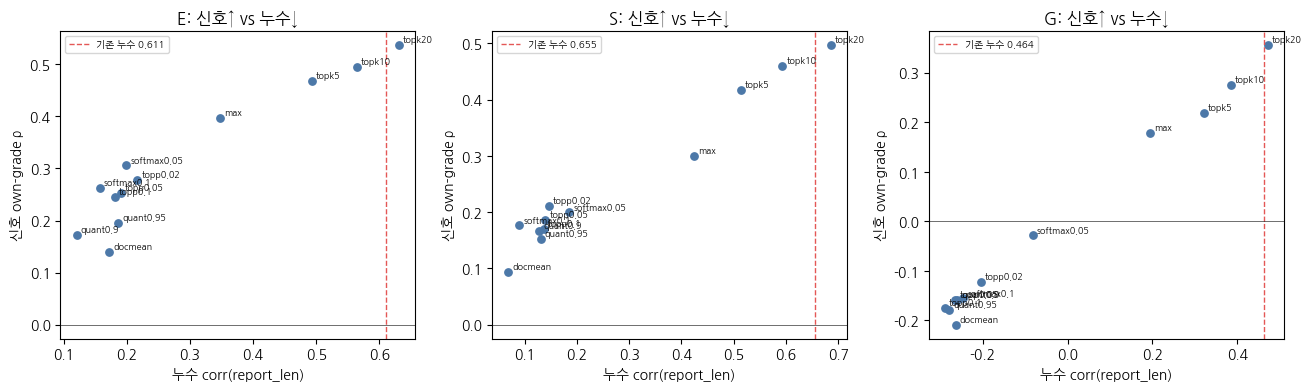

▶ 풀링 종합 (프론티어 score = 부분ρ − |누수|):
       pool  signal  partial  leak_abs  score
softmax0.05   0.160    0.086     0.155 -0.069
 softmax0.1   0.095    0.081     0.164 -0.083
   quant0.9   0.060    0.076     0.169 -0.093
   topp0.02   0.122    0.075     0.189 -0.114
    topp0.1   0.080    0.087     0.202 -0.115
   topp0.05   0.093    0.081     0.198 -0.117
  quant0.95   0.056    0.065     0.198 -0.134
    docmean   0.008    0.001     0.168 -0.167
        max   0.292    0.082     0.321 -0.239
      topk5   0.368    0.083     0.442 -0.359
     topk10   0.410    0.089     0.514 -0.425
     topk20   0.463    0.098     0.596 -0.498

추천 풀링(프론티어): softmax0.05

▶ E_cos 상위 3 문서:
     doc_id    E_cos  e_grade  report_len
042670_2024 0.467646      4.0       394.0
042670_2023 0.467510      5.0       406.0
042670_2022 0.463575      5.0       428.0
피처 저장: 07_v2_features_dense.csv

🚦 G2 (분량누수) — 채택 풀링 누수 vs 기존, 그리고 순수신호(부분 ρ):
  E: 누수 +0.198 (기존 0.611 → |누수|Δ +0.413) | 신호 ρ +0.306 | 순수 ρ +0.168
  S: 누수

In [10]:
# ── Step 6.2 · 신호↔누수 프론티어 · 풀링 채택(부분ρ−|누수| 프론티어) · G2 판정 ──
BASE_LEAK = {"E": 0.611, "S": 0.655, "G": 0.464}          # F3 기존(06) 누수 corr(n_sent, cosine)

# ── ① 시각화: 차원별 신호(y)–누수(x) 프론티어 (점이 직선이면 '신호=분량') ──
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, d in zip(axes, ["E", "S", "G"]):
    sub = res[res["dim"] == d]
    ax.scatter(sub["leak_corr"], sub["signal_rho"], s=28, color="#4C78A8")
    for _, r in sub.iterrows():
        ax.annotate(r["pool"], (r["leak_corr"], r["signal_rho"]), fontsize=6.5,
                    xytext=(3, 2), textcoords="offset points")
    ax.axvline(BASE_LEAK[d], color="#E45756", ls="--", lw=1, label=f"기존 누수 {BASE_LEAK[d]}")
    ax.axhline(0, color="k", lw=.4)
    ax.set_title(f"{d}: 신호↑ vs 누수↓"); ax.set_xlabel("누수 corr(report_len)")
    ax.set_ylabel("신호 own-grade ρ"); ax.legend(fontsize=7)
plt.show()

# ── 풀링 채택: 프론티어 = 부분ρ(순수신호)↑ − |누수|↓.  부분ρ 차이는 노이즈급이라 |누수|가 사실상 결정 ──
agg = (res.groupby("pool")
          .agg(signal=("signal_rho", "mean"), partial=("partial_rho", "mean"),
               leak_abs=("leak_corr", lambda x: x.abs().mean())).reset_index())
agg["score"] = agg["partial"] - agg["leak_abs"]
agg = agg.sort_values("score", ascending=False)
print("▶ 풀링 종합 (프론티어 score = 부분ρ − |누수|):"); print(agg.round(3).to_string(index=False))
CHOSEN = agg.iloc[0]["pool"]
print(f"\n추천 풀링(프론티어): {CHOSEN}")

# ── ② 샘플: 채택 풀링 피처 + E_cos 상위 3 ──
col = docscore_cache[CHOSEN]
feat = pd.DataFrame({"doc_id": doc_keys,
                     "stock_code": [k.split("_")[0] for k in doc_keys],
                     "fiscal_year": [int(k.split("_")[1]) for k in doc_keys],
                     "E_cos": col["E"], "S_cos": col["S"], "G_cos": col["G"],
                     "report_len": report_len,
                     "e_grade": grades["E"], "s_grade": grades["S"], "g_grade": grades["G"]})
print("\n▶ E_cos 상위 3 문서:")
print(feat.sort_values("E_cos", ascending=False).head(3)[["doc_id","E_cos","e_grade","report_len"]].to_string(index=False))
FEAT_CSV = DATA / "07_v2_features_dense.csv"              # 풀링 바꾸려면 CHOSEN 수정 후 재실행
feat.assign(pool=CHOSEN).to_csv(FEAT_CSV, index=False); print("피처 저장:", FEAT_CSV.name)

# ── 🚦 G2 (분량누수) + 순수신호 병기 ──
print("\n🚦 G2 (분량누수) — 채택 풀링 누수 vs 기존, 그리고 순수신호(부분 ρ):")
g2_ok = True
for d in ["E", "S", "G"]:
    r = res[(res.pool == CHOSEN) & (res.dim == d)]
    lk = float(r["leak_corr"].iloc[0]); sg = float(r["signal_rho"].iloc[0]); pr = float(r["partial_rho"].iloc[0])
    print(f"  {d}: 누수 {lk:+.3f} (기존 {BASE_LEAK[d]} → |누수|Δ {BASE_LEAK[d]-abs(lk):+.3f}) | 신호 ρ {sg:+.3f} | 순수 ρ {pr:+.3f}")
    if abs(lk) >= BASE_LEAK[d]: g2_ok = False
print(f"\n판정(누수축): {'PASS ✅ (|누수| 의미있게 감소)' if g2_ok else 'FAIL — 누수 미감소'}")
print("※ 단, '순수 ρ'(분량 통제 후)가 0 근처/음수인 차원은 언어신호가 사실상 없음(정직한 null). G3 에서 본격 판별.")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • 부분ρ 가 풀링과 무관하게 평평하면(E~.15·S~.10·G~0) 신호의 본질은 풀링이 아니라 '분량을 뺀 잔차'다.")
print(" • 그래서 채택은 '순수신호를 지키되 누수를 가장 적게'(프론티어) = 낮은-누수 + 높은-부분ρ 풀.")
print(" • 등급↔분량 ρ≈.58~.63 이 핵심 교란 — 회귀에서 report_len 통제는 '필수'이고, 통제 후 텍스트 계수가 진짜 결론.")
print("   ▶ REVIEW REQUIRED: 풀링 확정/변경 → Step 7(E/S/G_cos 확정 · G3 판별타당도 3×3 Spearman 대각지배).")

## Step 7 — 비지도 피처 확정 · **Gate 3 판별타당도** 〔Colab · §5.3 · F2〕

> [`plan/03_features.md`](../plan/03_features.md) §5.3 · [`plan/01_rationale.md`](../plan/01_rationale.md) §1(F2). 채택 풀링(**softmax0.05**)의 `E_cos`/`S_cos`/`G_cos` 확정.

- **3×3 Spearman 대각지배**: 각 피처가 '자기 차원' 등급과 가장 강하게 연관되는가. **raw + 분량통제(부분상관)** 두 버전.
- 기존 **F2 실패**: `cosine_E→S .428 > E .394`, 피처 간 **E–S .844**(단일요인). 화이트닝/풀링이 개선했는지 본다.
- **🚦 Gate 3 PASS** = (부분) 대각지배 성립. FAIL → 앵커 재설계(`02_anchors.md`) 또는 **단일 공시충실도 요인 인정**(P5), **회귀는 통합/PCA 중심**.
- ⚠ 6.2 까지 실행돼 `feat`(softmax0.05) 가 메모리에 있어야 함. 분량통제 부분상관이 핵심(raw 는 길이 교란).

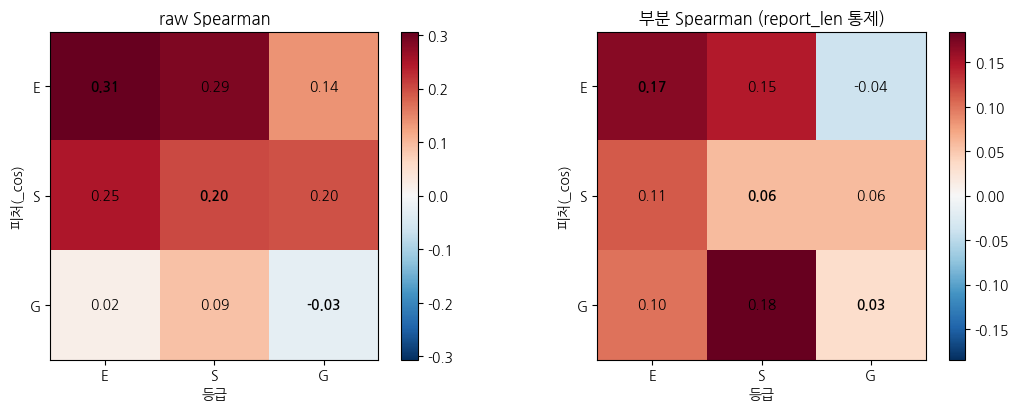

raw 대각지배 행: ['E'] | 부분 대각지배 행: ['E']

▶ raw 3×3 (피처×등급):
       e_grade  s_grade  g_grade
E_cos    0.306    0.285    0.136
S_cos    0.248    0.201    0.195
G_cos    0.018    0.090   -0.028

▶ partial 3×3 (report_len 통제):
       e_grade  s_grade  g_grade
E_cos    0.168    0.146   -0.038
S_cos    0.114    0.058    0.058
G_cos    0.100    0.185    0.032

▶ 피처 간 Spearman (기존 F2: E–S .844 / E–G .593 / S–G .646):
       E_cos  S_cos  G_cos
E_cos  1.000  0.479  0.123
S_cos  0.479  1.000  0.188
G_cos  0.123  0.188  1.000

▶ 단일요인 점검 (부분상관) — 각 피처의 e/s/g 등급 연관:
  E_cos: e=+0.168  s=+0.146  g=-0.038   (자기차원=E)
  S_cos: e=+0.114  s=+0.058  g=+0.058   (자기차원=S)
  G_cos: e=+0.100  s=+0.185  g=+0.032   (자기차원=G)

🚦 G3 (판별타당도): raw 대각지배 1/3 · 부분 대각지배 1/3
판정: FAIL/REVIEW — 부분 대각지배 미완성 → 앵커 재설계(02_anchors.md) 또는 단일요인 인정(P5)

[해석 가이드]
 • raw 대각지배가 성립해도 분량 교란일 수 있다 → 'report_len 통제 부분'이 진짜 판별타당도.
 • 부분 3×3 에서 각 행(피처)의 최댓값이 대각(자기 등급)이면 그 차원은 변별됨. G행은 ~0 라 대각지배 어려울 수 있음(F5 단일요인).
 • 피처 간 상관이 F2(.844)보다 낮아졌으면 

In [11]:
# ── Step 7.1 · 비지도 피처 확정 · G3 판별타당도(3×3 Spearman 대각지배) ─────────
from scipy.stats import spearmanr
# 채택 풀링(CHOSEN) 피처 feat 사용. raw + 분량통제(partial) 두 버전.
F = ["E_cos", "S_cos", "G_cos"]; Gd = ["e_grade", "s_grade", "g_grade"]; dims = ["E", "S", "G"]
rl = feat["report_len"].to_numpy()
def _rho(a, b): return spearmanr(a, b).correlation
def _prho(a, b, z):                       # partial spearman (z 통제)
    rab, raz, rbz = _rho(a, b), _rho(a, z), _rho(b, z)
    return (rab - raz * rbz) / np.sqrt(max(1e-9, (1 - raz**2) * (1 - rbz**2)))
Araw = np.zeros((3, 3)); Apar = np.zeros((3, 3))
for i, f in enumerate(F):
    for j, g in enumerate(Gd):
        Araw[i, j] = _rho(feat[f].to_numpy(), feat[g].to_numpy())
        Apar[i, j] = _prho(feat[f].to_numpy(), feat[g].to_numpy(), rl)

# ── ① 시각화: raw vs partial 3×3 히트맵 (행=피처, 열=등급, 대각=자기차원) ──
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, Mx, ttl in [(axes[0], Araw, "raw Spearman"), (axes[1], Apar, "부분 Spearman (report_len 통제)")]:
    v = max(0.05, np.abs(Mx).max()); im = ax.imshow(Mx, cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_xticks(range(3)); ax.set_xticklabels(dims); ax.set_yticks(range(3)); ax.set_yticklabels(dims)
    ax.set_xlabel("등급"); ax.set_ylabel("피처(_cos)")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{Mx[i,j]:.2f}", ha="center", va="center", fontsize=10,
                    fontweight="bold" if i == j else "normal")
    ax.set_title(ttl); fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()

def diagdom(M): return [dims[i] for i in range(3) if np.argmax(M[i]) == i]   # 행별 자기등급이 최대?
print("raw 대각지배 행:", diagdom(Araw), "| 부분 대각지배 행:", diagdom(Apar))
print("\n▶ raw 3×3 (피처×등급):");    print(pd.DataFrame(Araw, index=F, columns=Gd).round(3))
print("\n▶ partial 3×3 (report_len 통제):"); print(pd.DataFrame(Apar, index=F, columns=Gd).round(3))

# ── 피처 간 상관 (F2 기존: E–S .844 / E–G .593 / S–G .646) ──
FF = feat[F].corr(method="spearman")
print("\n▶ 피처 간 Spearman (기존 F2: E–S .844 / E–G .593 / S–G .646):"); print(FF.round(3))

# ── ② 샘플: 단일요인 점검 — 각 피처가 (e,s,g) 등급과 비슷하게 상관하나(부분) ──
print("\n▶ 단일요인 점검 (부분상관) — 각 피처의 e/s/g 등급 연관:")
for i, f in enumerate(F):
    print(f"  {f}: e={Apar[i,0]:+.3f}  s={Apar[i,1]:+.3f}  g={Apar[i,2]:+.3f}   (자기차원={dims[i]})")

# ── 🚦 G3 판정 (부분 대각지배가 진짜 판별력) ──
g3_par = len(diagdom(Apar)) == 3
print(f"\n🚦 G3 (판별타당도): raw 대각지배 {len(diagdom(Araw))}/3 · 부분 대각지배 {len(diagdom(Apar))}/3")
print("판정:", "PASS ✅ (부분 대각지배 완전 성립)" if g3_par
      else "FAIL/REVIEW — 부분 대각지배 미완성 → 앵커 재설계(02_anchors.md) 또는 단일요인 인정(P5)")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • raw 대각지배가 성립해도 분량 교란일 수 있다 → 'report_len 통제 부분'이 진짜 판별타당도.")
print(" • 부분 3×3 에서 각 행(피처)의 최댓값이 대각(자기 등급)이면 그 차원은 변별됨. G행은 ~0 라 대각지배 어려울 수 있음(F5 단일요인).")
print(" • 피처 간 상관이 F2(.844)보다 낮아졌으면 화이트닝/풀링이 단일요인성을 일부 완화한 것(부분 성공).")
print(" • FAIL이면: 앵커 재설계 또는 '단일 공시충실도 요인' 정직 인정 → 회귀는 통합/PCA 합성요인 중심(P5).")
print("   ▶ REVIEW REQUIRED: G3 결과 확인 → Step 8 지도 프로브(G5, GroupKFold)로 '추출 가능 차원신호 상한' 추정.")

## Step 8 — 지도 프로브 (예측 상한 벤치마크) · **Gate 5** 〔Colab · §5.4〕

> [`plan/03_features.md`](../plan/03_features.md) §5.4. 목적 = 비지도 cosine이 *놓쳤을* 차원신호의 **상한**을 정직 추정(예측 최대치용 — "독립 패턴" 주장 아님).

- **표현**: 문서평균 임베딩(1024d). n=381≪1024 → 폴드 내 **StandardScaler + PCA(whiten, 50d)**. 모델 = RidgeCV(폴드 내 alpha).
- **🚦 Gate 5 누설 방지(핵심)**: **GroupKFold(기업 stock_code)** — 같은 기업 3년이 train/test 동시 X. **OOF 예측만** 사용. 모든 적합(scaler·PCA·alpha)은 train 폴드 내. (위반 시 프로브 폐기)
- **핵심 비교**: probe OOF **부분ρ**(분량 통제) vs cosine 부분ρ. 격차 작으면 *임베딩에 차원신호 거의 없음*(정직한 귀무, F5 보강), 크면 cosine이 못 뽑은 신호.
- 산출 `E_sup/S_sup/G_sup` → `07_v2_features_supervised.csv`. ⚠ 6.2 까지 실행돼 `E`·`offs`·`feat` 메모리 필요.

문서평균 임베딩 (381, 1024) | 기업 수 127 | 문서 381

▶ 지도 프로브 vs 비지도 cosine (부분ρ=분량 통제 순수신호):
     cosine 부분ρ  probe OOF ρ  probe 부분ρ(상한)  probe leak(ρ,len)
dim                                                           
E         0.168        0.548          0.274              0.602
S         0.058        0.558          0.275              0.648
G         0.032        0.464          0.192              0.584


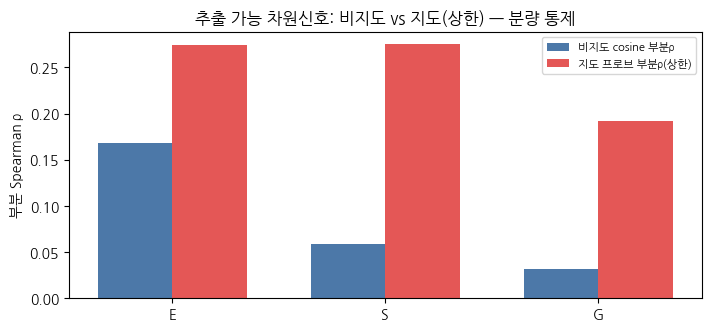


▶ E_sup 상·하위 문서 (예측 vs 실제 e등급):
  030200_2022  E_sup=+5.11  실제 e=3  report_len=1299
  086790_2024  E_sup=+5.07  실제 e=4  report_len=1241
  000760_2022  E_sup=+0.16  실제 e=1  report_len=157
  000760_2023  E_sup=-0.03  실제 e=1  report_len=165

🚦 G5 (누설 방지): GroupKFold(기업) + OOF 예측만 + 폴드내 적합 → 충족 ✅ (그룹 누설 assert 통과)

[해석 가이드]
 • probe 부분ρ(상한)이 cosine 부분ρ 와 비슷하면 → 임베딩에 그 차원신호가 '거의 없음'(정직한 귀무, F5 보강).
 • probe 부분ρ 가 cosine 보다 크게 높으면 → cosine/앵커가 놓친 신호 존재(차원특정 X, 예측 상한↑).
 • probe leak(ρ,len)이 크면 프로브가 '길이'를 학습한 것 → 그래서 부분ρ(길이 통제)가 진짜 상한.
 • 상한도 E>S>G·G≈0 이면, '사업보고서 언어로는 G등급을 못 맞힌다'가 데이터의 결론(앵커·방법 문제 아님).
   ▶ REVIEW REQUIRED: 상한 확인 → Step 9 분석테이블 병합(피처+등급+통제) → Step 10 진단(G4 VIF) → Step 11 회귀.


In [12]:
# ── Step 8.1 · 지도 프로브 (상한 벤치마크) · G5 누설안전 GroupKFold OOF ─────────
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from scipy.stats import spearmanr

# 표현: 화이트닝 아닌 raw 문서평균 임베딩(폴드 내 StandardScaler+PCA(whiten)로 누설없이 처리)
doc_emb = np.stack([E[offs[i]:offs[i + 1]].mean(0) for i in range(ndoc)]).astype(np.float32)  # (381,1024)
groups = np.array([k.split("_")[0] for k in doc_keys])     # 기업 id(stock_code) — 패널 누설 차단 그룹
rl = feat["report_len"].to_numpy()
print(f"문서평균 임베딩 {doc_emb.shape} | 기업 수 {len(set(groups))} | 문서 {ndoc}")

def _prho(a, b, z):                                        # partial spearman (z 통제)
    ra, rz, rbz = spearmanr(a, b).correlation, spearmanr(a, z).correlation, spearmanr(b, z).correlation
    return (ra - rz * rbz) / np.sqrt(max(1e-9, (1 - rz**2) * (1 - rbz**2)))

def oof_predict(X, y, groups, n_pca=50, n_splits=5):
    oof = np.full(len(y), np.nan); gkf = GroupKFold(n_splits=n_splits)
    for tr, te in gkf.split(X, y, groups):
        assert not (set(groups[tr]) & set(groups[te])), "그룹 누설! 같은 기업이 train/test 동시"
        sc = StandardScaler().fit(X[tr])
        k = min(n_pca, len(tr) - 1, X.shape[1])
        pca = PCA(n_components=k, whiten=True, random_state=0).fit(sc.transform(X[tr]))   # 폴드 내 화이트닝
        Ztr = pca.transform(sc.transform(X[tr])); Zte = pca.transform(sc.transform(X[te]))
        m = RidgeCV(alphas=np.logspace(-1, 4, 12)).fit(Ztr, y[tr])                          # alpha 폴드 내 선택
        oof[te] = m.predict(Zte)
    return oof

dims = ["E", "S", "G"]; Gd = {"E": "e_grade", "S": "s_grade", "G": "g_grade"}
Fc = {"E": "E_cos", "S": "S_cos", "G": "G_cos"}
rows = []
sup_oof = {}
for d in dims:
    y = feat[Gd[d]].to_numpy()
    oof = oof_predict(doc_emb, y, groups); sup_oof[d] = oof
    sup_raw = spearmanr(oof, y).correlation                 # 프로브 OOF 신호(분량 포함)
    sup_par = _prho(oof, y, rl)                             # 프로브 OOF 순수신호(분량 통제) = 상한
    sup_leak = spearmanr(oof, rl).correlation               # 프로브가 길이를 학습했나
    cos_par = _prho(feat[Fc[d]].to_numpy(), y, rl)          # 비지도 cosine 순수신호(비교)
    rows.append((d, cos_par, sup_raw, sup_par, sup_leak))
tab = pd.DataFrame(rows, columns=["dim", "cosine 부분ρ", "probe OOF ρ", "probe 부분ρ(상한)", "probe leak(ρ,len)"]).set_index("dim")
print("\n▶ 지도 프로브 vs 비지도 cosine (부분ρ=분량 통제 순수신호):"); print(tab.round(3).to_string())

# 문서당 E_sup/S_sup/G_sup 저장(병합용)
sup_df = pd.DataFrame({"doc_id": doc_keys, **{f"{d}_sup": sup_oof[d] for d in dims}})
sup_df.to_csv(DATA / "07_v2_features_supervised.csv", index=False)

# ── ① 시각화: cosine 부분ρ vs probe 부분ρ(상한) ──
fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
xs = np.arange(3); w = 0.35
ax.bar(xs - w/2, tab["cosine 부분ρ"], w, label="비지도 cosine 부분ρ", color="#4C78A8")
ax.bar(xs + w/2, tab["probe 부분ρ(상한)"], w, label="지도 프로브 부분ρ(상한)", color="#E45756")
ax.set_xticks(xs); ax.set_xticklabels(dims); ax.axhline(0, color="k", lw=.5); ax.legend(fontsize=8)
ax.set_title("추출 가능 차원신호: 비지도 vs 지도(상한) — 분량 통제"); ax.set_ylabel("부분 Spearman ρ")
plt.show()

# ── ② 샘플: E 차원 예측 vs 실제 등급 (상·하위 2건) ──
od = np.argsort(-sup_oof["E"])
print("\n▶ E_sup 상·하위 문서 (예측 vs 실제 e등급):")
for i in list(od[:2]) + list(od[-2:]):
    print(f"  {doc_keys[i]}  E_sup={sup_oof['E'][i]:+.2f}  실제 e={feat['e_grade'].iloc[i]:.0f}  report_len={int(rl[i])}")

# ── 🚦 G5 + 해석 ──
print("\n🚦 G5 (누설 방지): GroupKFold(기업) + OOF 예측만 + 폴드내 적합 → 충족 ✅ (그룹 누설 assert 통과)")
print("\n[해석 가이드]")
print(" • probe 부분ρ(상한)이 cosine 부분ρ 와 비슷하면 → 임베딩에 그 차원신호가 '거의 없음'(정직한 귀무, F5 보강).")
print(" • probe 부분ρ 가 cosine 보다 크게 높으면 → cosine/앵커가 놓친 신호 존재(차원특정 X, 예측 상한↑).")
print(" • probe leak(ρ,len)이 크면 프로브가 '길이'를 학습한 것 → 그래서 부분ρ(길이 통제)가 진짜 상한.")
print(" • 상한도 E>S>G·G≈0 이면, '사업보고서 언어로는 G등급을 못 맞힌다'가 데이터의 결론(앵커·방법 문제 아님).")
print("   ▶ REVIEW REQUIRED: 상한 확인 → Step 9 분석테이블 병합(피처+등급+통제) → Step 10 진단(G4 VIF) → Step 11 회귀.")

## Step 8.2 — 판별타당도 정합 (3트랙 공통 잣대) 〔Colab〕

> 종합 비교를 위해 **TF‑IDF 트랙(05b/05c)과 동일한 통제 = {`log(II+IV+VI)` 길이, `log_assets` 규모}** 로 부분 3×3 Spearman을 재계산. (G3는 `report_len`만 통제했으므로 size 포함해 공정 비교.)
> 통제변수 파일은 TF‑IDF와 공용: `data/processed/industry_sector_mapping.csv`(sector·log_assets)·`dart_section_lengths.csv`(len_II/IV/VI). 이 셀은 8.1 까지 실행돼 `feat`·`sup_df` 가 메모리에 있어야 함.

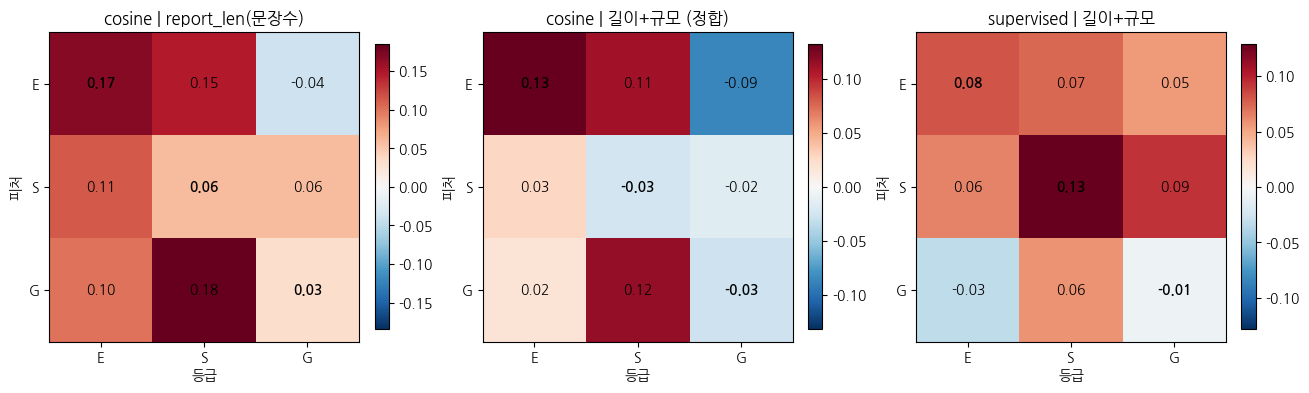

부분 대각지배 — cosine|report_len: ['E'] | cosine|길이+규모: ['E'] | supervised|길이+규모: ['E', 'S']
  cosine|길이+규모 대각: E=+0.132 S=-0.025 G=-0.027
  supervised|길이+규모 대각: E=+0.081 S=+0.129 G=-0.007

[해석 가이드]
 • 3트랙 공통 잣대(길이+규모 통제 부분 3×3). report_len(문장수)→길이+규모로 바꾸면 규모(1차 교란)가 추가로 대각을 깎을 수 있다.
 • 참고(같은 잣대) — TF-IDF seed: 대각 E.20/S.10/G.17(3/3) · 확장: E.20/S.07/G.13(2/3). Dense는 위 가운데 패널로 비교.
 • supervised(상한)는 cosine보다 대각이 클 수 있음(임베딩에 신호는 있으나 cosine이 덜 뽑음). 종합 슬라이드 ⓐ에 3트랙 가운데 패널을 나란히.


In [18]:
# ── Step 8.2 · 판별타당도 정합: 부분 3×3 (길이+규모 통제) — 3트랙 공통 잣대 ──────
# TF-IDF 트랙(05b/05c)과 동일하게 {log(core 문자수), log(자산)} 통제한 부분 Spearman 3×3.
# 필요: feat(6.2 cosine 피처)·sup_df(8.1 supervised) 메모리 + 통제변수 CSV 2개.
from scipy.stats import rankdata
_zf = lambda s: s.astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(6)
_map = pd.read_csv(PROJECT/"data"/"processed"/"industry_sector_mapping.csv", dtype={"stock_code": "string"})
_len = pd.read_csv(PROJECT/"data"/"processed"/"dart_section_lengths.csv", dtype={"stock_code": "string"})
_map["stock_code"] = _zf(_map["stock_code"]); _map["fiscal_year"] = _map["fiscal_year"].astype(int)
_len["stock_code"] = _zf(_len["stock_code"]); _len["fiscal_year"] = _len["fiscal_year"].astype(int)
_len["log_core_len"] = np.log(_len["len_II"] + _len["len_IV"] + _len["len_VI"])

C = feat.merge(sup_df, on="doc_id", how="left")
C["stock_code"] = _zf(C["stock_code"]); C["fiscal_year"] = C["fiscal_year"].astype(int)
C = C.merge(_map[["stock_code", "fiscal_year", "log_assets"]], on=["stock_code", "fiscal_year"], how="left")
C = C.merge(_len[["stock_code", "fiscal_year", "log_core_len"]], on=["stock_code", "fiscal_year"], how="left")
assert C[["log_assets", "log_core_len"]].notna().all().all(), "통제변수 병합 결측 — CSV 경로/키 확인"

def _pspear(x, y, Zcols):
    rx = rankdata(x); ry = rankdata(y)
    Z = np.column_stack([np.ones(len(rx))] + [rankdata(C[c]) for c in Zcols])
    ex = rx - Z @ np.linalg.lstsq(Z, rx, rcond=None)[0]
    ey = ry - Z @ np.linalg.lstsq(Z, ry, rcond=None)[0]
    return float(np.corrcoef(ex, ey)[0, 1])

Gd = {"E": "e_grade", "S": "s_grade", "G": "g_grade"}
def mat3(pref, Zcols):
    return np.array([[_pspear(C[f"{d}_{pref}"], C[Gd[g]], Zcols) for g in ["E", "S", "G"]] for d in ["E", "S", "G"]])
M_rl  = mat3("cos", ["report_len"])             # 기존 G3 방식(문장수만)
M_ls  = mat3("cos", ["log_core_len", "log_assets"])   # 정합: 길이+규모
M_sup = mat3("sup", ["log_core_len", "log_assets"])   # 지도프로브 OOF, 길이+규모

# ── ① 시각화: 3개 히트맵 ──
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, M, ttl in [(axes[0], M_rl, "cosine | report_len(문장수)"),
                   (axes[1], M_ls, "cosine | 길이+규모 (정합)"),
                   (axes[2], M_sup, "supervised | 길이+규모")]:
    v = max(.05, np.abs(M).max()); im = ax.imshow(M, cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_xticks(range(3)); ax.set_xticklabels(["E", "S", "G"]); ax.set_yticks(range(3)); ax.set_yticklabels(["E", "S", "G"])
    ax.set_xlabel("등급"); ax.set_ylabel("피처")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontweight="bold" if i == j else "normal")
    ax.set_title(ttl); fig.colorbar(im, ax=ax, fraction=.046)
plt.show()
dd = lambda M: [["E", "S", "G"][i] for i in range(3) if np.argmax(M[i]) == i]
print("부분 대각지배 — cosine|report_len:", dd(M_rl), "| cosine|길이+규모:", dd(M_ls), "| supervised|길이+규모:", dd(M_sup))
for nm, M in [("cosine|길이+규모", M_ls), ("supervised|길이+규모", M_sup)]:
    print(f"  {nm} 대각: E={M[0,0]:+.3f} S={M[1,1]:+.3f} G={M[2,2]:+.3f}")

# ── ③ 해석 가이드 ──
print("\n[해석 가이드]")
print(" • 3트랙 공통 잣대(길이+규모 통제 부분 3×3). report_len(문장수)→길이+규모로 바꾸면 규모(1차 교란)가 추가로 대각을 깎을 수 있다.")
print(" • 참고(같은 잣대) — TF-IDF seed: 대각 E.20/S.10/G.17(3/3) · 확장: E.20/S.07/G.13(2/3). Dense는 위 가운데 패널로 비교.")
print(" • supervised(상한)는 cosine보다 대각이 클 수 있음(임베딩에 신호는 있으나 cosine이 덜 뽑음). 종합 슬라이드 ⓐ에 3트랙 가운데 패널을 나란히.")

## Step 9 — 분석테이블 병합 (피처 + KCGS 등급 + 통제변수) 〔Colab · §8 단계 9〕

> **무엇**: cosine 피처(`E/S/G_cos`, 6.2)·지도프로브(`E/S/G_sup`, 8.1)·KCGS 등급(차원별 + 통합)·통제변수(규모 `log_assets`·업종 `sector` 대분류·핵심분량 `log(II+IV+VI)` 문자수)를 `doc_id={stock_code}_{fiscal_year}` 로 **1:1 병합**한 회귀용 단일 테이블 `07_v2_analysis_table.csv` 생성.
> **왜 이 스펙**: TF‑IDF 트랙(05b/05c)과 **동일 통제·동일 z‑score·동일 기준범주(업종=1차금속, 연도=2022)** 로 맞춰 3트랙 종합표를 같은 잣대로 비교(통일안). 분량 통제 주력 = `log_core_doc_len`(문자수, TF‑IDF와 동일 정의), 보조 = `report_len`(문장수).
> **선행 조건**: 8.1·8.2 까지 실행돼 `feat`·`sup_df` 가 메모리에 있어야 함(없으면 셀이 자동 CSV 폴백). 통제 CSV 2개(`industry_sector_mapping.csv`·`dart_section_lengths.csv`)는 TF‑IDF와 공용.

피처 출처: 메모리 (feat·sup_df)

분석테이블 저장: 07_v2_analysis_table.csv  shape=(381, 37)  (행 381 = 127사×3년)
업종 더미: ['sector_IT·통신·미디어', 'sector_금융·보험', 'sector_기계·전자·운송장비', 'sector_유통·물류·건설·기타', 'sector_음식료·소비재', 'sector_제약·바이오·의료', 'sector_화학·소재'] 
연도 더미: ['year_2023', 'year_2024']


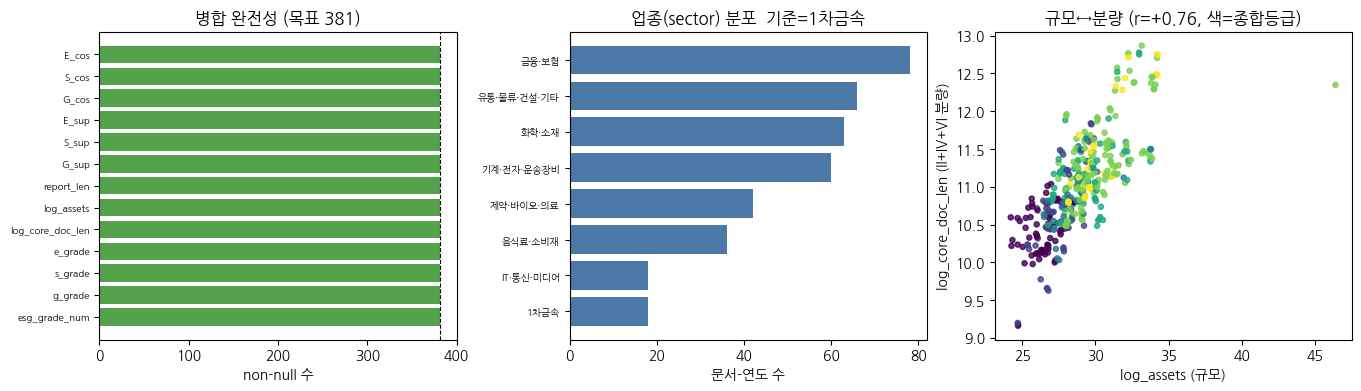


▶ 분석테이블 샘플 2건:
     doc_id    E_cos    G_cos    E_sup    G_sup  report_len  log_assets  log_core_doc_len    sector  e_grade  g_grade  esg_grade_num
000020_2022 0.271816 0.215489 2.206611 2.362369       229.0   26.856960         10.637753 제약·바이오·의료      1.0      1.0              1
000020_2023 0.271979 0.211893 2.363753 2.498018       233.0   27.060043         10.660994 제약·바이오·의료      2.0      1.0              1

▶ 텍스트/통제/등급 상관 일부 (피어슨):
                    E_cos_z  G_cos_z  log_assets_z  log_core_doc_len_z  esg_grade_num
E_cos_z                1.00     0.20          0.24                0.17           0.22
G_cos_z                0.20     1.00          0.08               -0.09           0.04
log_assets_z           0.24     0.08          1.00                0.76           0.66
log_core_doc_len_z     0.17    -0.09          0.76                1.00           0.62
esg_grade_num          0.22     0.04          0.66                0.62           1.00

[해석 가이드]
 • 행 381 = 127사×3년, 키 doc_id={sto

In [14]:
# ── Step 9 · 분석테이블 병합 (cosine+supervised 피처 + KCGS 등급 + 통제변수) ──────────
# 입력: feat(6.2)·sup_df(8.1) 메모리(없으면 CSV 폴백) + 통제 CSV 2개 + company_master(통합등급).
# 키: doc_id = {stock_code}_{fiscal_year} (stock_code zfill6). 산출: 07_v2_analysis_table.csv (회귀용 단일 테이블).
from scipy.stats import zscore

_zf = lambda s: s.astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(6)
GRADE_MAP = {"S": 6, "A+": 5, "A": 4, "B+": 3, "B": 2, "C": 1, "D": 0}   # KCGS 순서형, TF-IDF 트랙과 동일

# (0) 피처 로드 — 메모리 우선, 없으면 Colab CSV 폴백
try:
    _feat, _sup = feat.copy(), sup_df.copy(); print("피처 출처: 메모리 (feat·sup_df)")
except NameError:
    _feat = pd.read_csv(DATA / "07_v2_features_dense.csv", dtype={"stock_code": "string"})
    _sup  = pd.read_csv(DATA / "07_v2_features_supervised.csv"); print("피처 출처: CSV 폴백")

A = _feat.merge(_sup, on="doc_id", how="left", validate="one_to_one")
A["stock_code"] = _zf(A["stock_code"]); A["fiscal_year"] = A["fiscal_year"].astype(int)
n0 = len(A)

# (1) 통제변수: 규모(log_assets)·업종(sector 대분류)·핵심분량(log(II+IV+VI) 문자수)
_map = pd.read_csv(PROJECT/"data"/"processed"/"industry_sector_mapping.csv", dtype={"stock_code": "string"})
_len = pd.read_csv(PROJECT/"data"/"processed"/"dart_section_lengths.csv",    dtype={"stock_code": "string"})
_map["stock_code"] = _zf(_map["stock_code"]); _map["fiscal_year"] = _map["fiscal_year"].astype(int)
_len["stock_code"] = _zf(_len["stock_code"]); _len["fiscal_year"] = _len["fiscal_year"].astype(int)
_len["log_core_doc_len"] = np.log(_len["len_II"] + _len["len_IV"] + _len["len_VI"])   # 주력 분량(문자수)
A = A.merge(_map[["stock_code", "fiscal_year", "sector", "log_assets"]],
            on=["stock_code", "fiscal_year"], how="left", validate="one_to_one")
A = A.merge(_len[["stock_code", "fiscal_year", "log_core_doc_len"]],
            on=["stock_code", "fiscal_year"], how="left", validate="one_to_one")

# (2) 통합 KCGS 등급(통합 회귀 종속변수) — company_master.csv. (차원별 e/s/g_grade 는 feat 에 이미 수치화됨)
_gm = pd.read_csv(PROJECT/"data"/"raw"/"company_master.csv", dtype={"stock_code": "string"})
_gm["stock_code"] = _zf(_gm["stock_code"]); _gm["fiscal_year"] = _gm["fiscal_year"].astype(int)
_gm["esg_grade_num"] = _gm["esg_grade"].map(GRADE_MAP)
A = A.merge(_gm[["stock_code", "fiscal_year", "esg_grade", "esg_grade_num"]],
            on=["stock_code", "fiscal_year"], how="left", validate="one_to_one")

# (3) 병합 무결성: 행수 불변 · 1:1 · 통제/등급 결측 0
ctrl_cols = ["log_assets", "log_core_doc_len", "sector", "esg_grade_num", "e_grade", "s_grade", "g_grade"]
miss = A[ctrl_cols].isna().sum()
assert len(A) == n0 == 381, f"행수 변동! {n0}→{len(A)} (1:1 깨짐)"
assert miss.sum() == 0, f"통제/등급 결측:\n{miss[miss > 0]}"

# (4) 회귀-준비 파생열: z-score(통제·텍스트, 모집단 std=StandardScaler) + 업종/연도 더미(기준 1차금속·2022)
ZCOLS = ["E_cos", "S_cos", "G_cos", "E_sup", "S_sup", "G_sup", "log_assets", "log_core_doc_len", "report_len"]
for c in ZCOLS:
    A[c + "_z"] = zscore(A[c].astype(float), ddof=0)          # TF-IDF 트랙과 동일 z-score
sector_cats = ["1차금속"] + sorted(s for s in A["sector"].unique() if s != "1차금속")
A["sector"] = pd.Categorical(A["sector"], categories=sector_cats)
sec_dum = pd.get_dummies(A["sector"], prefix="sector", drop_first=True).astype(int)   # 기준=1차금속(드롭)
yr_dum  = pd.get_dummies(A["fiscal_year"].astype(int), prefix="year", drop_first=True).astype(int)  # 기준=2022
A = pd.concat([A, sec_dum, yr_dum], axis=1)
A["high_esg"] = (A["esg_grade_num"] >= 4).astype(int)        # 이진 강건성(A 이상=1)

ANALYSIS_CSV = DATA / "07_v2_analysis_table.csv"
A.to_csv(ANALYSIS_CSV, index=False)
print(f"\n분석테이블 저장: {ANALYSIS_CSV.name}  shape={A.shape}  (행 {len(A)} = 127사×3년)")
print("업종 더미:", list(sec_dum.columns), "\n연도 더미:", list(yr_dum.columns))

# ── ① 시각화: 병합 완전성 · 업종 분포 · 규모↔분량 산점 ──
key_cols = ["E_cos", "S_cos", "G_cos", "E_sup", "S_sup", "G_sup", "report_len",
            "log_assets", "log_core_doc_len", "e_grade", "s_grade", "g_grade", "esg_grade_num"]
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.8), constrained_layout=True)
nn = A[key_cols].notna().sum()
ax[0].barh(range(len(nn)), nn.values, color=np.where(nn.values == len(A), "#54A24B", "#E45756"))
ax[0].set_yticks(range(len(nn))); ax[0].set_yticklabels(nn.index, fontsize=7); ax[0].invert_yaxis()
ax[0].axvline(len(A), color="k", ls="--", lw=.8); ax[0].set_title(f"병합 완전성 (목표 {len(A)})"); ax[0].set_xlabel("non-null 수")
sc = A["sector"].value_counts().sort_values()
ax[1].barh(range(len(sc)), sc.values, color="#4C78A8"); ax[1].set_yticks(range(len(sc)))
ax[1].set_yticklabels(sc.index, fontsize=7); ax[1].set_title("업종(sector) 분포  기준=1차금속"); ax[1].set_xlabel("문서-연도 수")
ax[2].scatter(A["log_assets"], A["log_core_doc_len"], s=14, c=A["esg_grade_num"], cmap="viridis", alpha=.8)
ax[2].set_xlabel("log_assets (규모)"); ax[2].set_ylabel("log_core_doc_len (II+IV+VI 분량)")
ax[2].set_title(f"규모↔분량 (r={A['log_assets'].corr(A['log_core_doc_len']):+.2f}, 색=종합등급)")
plt.show()

# ── ② 샘플: 실제 2건 raw (피처+통제+등급) + 핵심 상관 ──
show = ["doc_id", "E_cos", "G_cos", "E_sup", "G_sup", "report_len",
        "log_assets", "log_core_doc_len", "sector", "e_grade", "g_grade", "esg_grade_num"]
print("\n▶ 분석테이블 샘플 2건:")
print(A[show].head(2).to_string(index=False))
print("\n▶ 텍스트/통제/등급 상관 일부 (피어슨):")
print(A[["E_cos_z", "G_cos_z", "log_assets_z", "log_core_doc_len_z", "esg_grade_num"]].corr().round(2).to_string())

# ── ③ 해석 가이드 + 🚦 판정 ──
print("\n[해석 가이드]")
print(f" • 행 {len(A)} = 127사×3년, 키 doc_id={{stock_code}}_{{fiscal_year}} 1:1. 모든 핵심열 non-null=목표(초록)면 병합 OK.")
print(" • 분량 통제 2종: log_core_doc_len(문자수=주력, TF-IDF와 동일) + report_len(문장수=보조 robustness).")
print(" • 통제 z-score(모집단 std)·업종 기준=1차금속·연도 기준=2022 → Step11 계수를 TF-IDF 트랙과 같은 잣대로 비교.")
print(" • 경계: stock_code zfill(6) 필수(industry_sector_mapping 미패딩). 규모↔분량 상관 높으면 Step10 VIF 주시.")
print(f"\n🚦 Step 9 (분석테이블 병합): 행수 {len(A)}/381 · 통제·등급 결측 {int(miss.sum())} · 1:1 검증 통과")
print("   판정: PASS ✅ (asserts 통과).  ▶ 다음: Step 10 진단(대각지배·누수·수렴·G4 VIF<10) → Step 11 회귀.")

## Step 10 — 진단 (판별·누수·수렴타당도 · **Gate 4 VIF<10**) 〔Colab · §6.5 · §7〕

> 회귀(Step 11) 직전 마지막 게이트. **G4 = 완전모형 VIF<10** — 통합모형(E/S/G 텍스트 동시투입)에서 텍스트피처·통제 간 다중공선성 확인. 부수 진단(§7): ① 분량 누수(문장수 `report_len`·문자수 `log_core_doc_len` 2종 기준, 베이스라인 E.611/S.655/G.464 대비) ② 수렴타당도(덴스 cosine ↔ TF-IDF seed 3×3, 베이스라인 06 대각 E.503/S.428/G.288 대비) ③ 대각지배는 8.2(부분 3×3, 길이+규모 통제)에서 확정 → 여기선 재확인.
> 입력: `A`(분석테이블, Step 9; 없으면 CSV 폴백). TF-IDF seed 피처 `05_tfidf_seed_features.parquet`(Colab Drive 동기화 시) — 없으면 수렴 단계만 자동 skip.

통제 RHS: log_core_doc_len_z·log_assets_z + 업종더미 7 + 연도더미 2

▶ G4 — 모형별 최대 VIF (임계 10):
  통합 cosine      maxVIF= 4.89  (sector_금융·보험)  OK
  통합 supervised  maxVIF= 9.68  (E_sup_z)  OK
  차원 E cosine    maxVIF= 4.83  (sector_금융·보험)  OK
  차원 S cosine    maxVIF= 4.36  (sector_금융·보험)  OK
  차원 G cosine    maxVIF= 4.36  (sector_금융·보험)  OK

▶ 통합 cosine 모형 VIF 전체:
              term  vif
      sector_금융·보험 4.89
sector_유통·물류·건설·기타 4.13
      sector_화학·소재 3.96
 sector_기계·전자·운송장비 3.76
  sector_제약·바이오·의료 3.19
      log_assets_z 3.07
    sector_음식료·소비재 2.82
log_core_doc_len_z 2.81
  sector_IT·통신·미디어 2.05
           E_cos_z 1.42
         year_2023 1.34
         year_2024 1.34
           S_cos_z 1.19
           G_cos_z 1.18

▶ 분량 누수 (Spearman; 기존 cosine 누수 E.611/S.655/G.464 대비):
         ρ(report_len 문장수)  ρ(log_core_doc_len 문자수)
feature                                            
E_cos                0.288                    0.231
E_sup                0.602                    0.605
S_cos                

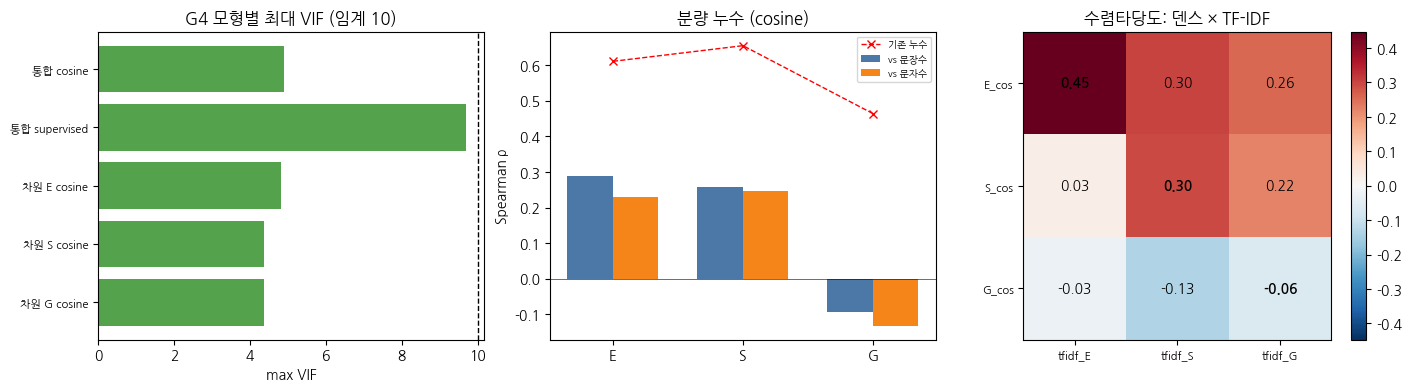


▶ 최악 VIF 항(통합 cosine) 상위 3:
              term  vif
      sector_금융·보험 4.89
sector_유통·물류·건설·기타 4.13
      sector_화학·소재 3.96

[해석 가이드]
 • G4(VIF): 텍스트피처(E/S/G_cos) 간 공선성은 화이트닝+하위앵커로 이미 붕괴(F2 .844→.479) → 통합모형도 <10 예상.
 • 진짜 공선성 후보는 log_core_doc_len_z↔log_assets_z(r≈.76) — 하지만 VIF≈1/(1-.76²)≈2.4 로 <10. 규모·길이 둘 다 유지.
 • 누수: 채택풀(softmax0.05)이라 cosine 누수는 기존(.46~.66)보다 낮아야 정상(G2 PASS 재확인). 문자수 기준도 같이 본다.
 • 수렴: 덴스 cosine 대각이 TF-IDF seed 대각(.50/.43/.29)과 같은 방향/유사하면 두 표현이 일치(수렴) — G 약함은 공통.

🚦 G4 (다중공선성): 모든 완전모형 max VIF < 10 → PASS ✅
   ▶ 다음: Step 11 회귀(차원별×통합 × {순서형·이진·OLS} × {cosine·supervised}, 기업 cluster SE, 단계적 통제).


In [15]:
# ── Step 10 · 진단: 누수 · 수렴타당도 · G4 VIF (완전모형 공선성) ───────────────────
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from scipy.stats import spearmanr

_zf = lambda s: s.astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(6)
try:
    A
except NameError:
    A = pd.read_csv(DATA / "07_v2_analysis_table.csv", dtype={"stock_code": "string"})
    A["stock_code"] = _zf(A["stock_code"]); A["fiscal_year"] = A["fiscal_year"].astype(int)
EsG = ["E", "S", "G"]
sector_cols = sorted(c for c in A.columns if c.startswith("sector_"))
year_cols   = sorted(c for c in A.columns if c.startswith("year_"))
CTRL = ["log_core_doc_len_z", "log_assets_z"] + sector_cols + year_cols
print(f"통제 RHS: log_core_doc_len_z·log_assets_z + 업종더미 {len(sector_cols)} + 연도더미 {len(year_cols)}")

# ── ① G4 VIF (하드 게이트) — 완전모형 5종 ──
def vif_table(cols):
    X = sm.add_constant(A[cols].astype(float), has_constant="add")
    return pd.DataFrame({"term": cols,
                         "vif": [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]})
MODELS = {
    "통합 cosine":     ["E_cos_z", "S_cos_z", "G_cos_z"] + CTRL,
    "통합 supervised": ["E_sup_z", "S_sup_z", "G_sup_z"] + CTRL,
    "차원 E cosine":   ["E_cos_z"] + CTRL,
    "차원 S cosine":   ["S_cos_z"] + CTRL,
    "차원 G cosine":   ["G_cos_z"] + CTRL,
}
vif_all = {name: vif_table(cols) for name, cols in MODELS.items()}
vif_max = {name: v["vif"].max() for name, v in vif_all.items()}
g4_ok = all(m < 10 for m in vif_max.values())
print("\n▶ G4 — 모형별 최대 VIF (임계 10):")
for name, m in vif_max.items():
    worst = vif_all[name].sort_values("vif").iloc[-1]
    print(f"  {name:14s} maxVIF={m:5.2f}  ({worst['term']})  {'OK' if m < 10 else '⚠'}")
print("\n▶ 통합 cosine 모형 VIF 전체:")
print(vif_all["통합 cosine"].sort_values("vif", ascending=False).round(2).to_string(index=False))

# ── ② 분량 누수 진단 (문장수·문자수 2종) ──
BASE_LEAK = {"E": 0.611, "S": 0.655, "G": 0.464}            # F3 기존(06) 누수 corr(report_len, cosine)
leak_rows = []
for d in EsG:
    for kind in ["cos", "sup"]:
        f = A[f"{d}_{kind}"]
        leak_rows.append((f"{d}_{kind}", spearmanr(f, A["report_len"]).correlation,
                          spearmanr(f, A["log_core_doc_len"]).correlation))
leak = pd.DataFrame(leak_rows, columns=["feature", "ρ(report_len 문장수)", "ρ(log_core_doc_len 문자수)"]).set_index("feature")
print("\n▶ 분량 누수 (Spearman; 기존 cosine 누수 E.611/S.655/G.464 대비):")
print(leak.round(3).to_string())

# ── ③ 수렴타당도: 덴스 cosine ↔ TF-IDF seed (3×3, 베이스라인 06 대각 E.503/S.428/G.288) ──
BASE_CONV = {"E": 0.503, "S": 0.428, "G": 0.288}
CM = None
try:
    tf = pd.read_parquet(DATA / "05_tfidf_seed_features.parquet")
    tf["stock_code"] = _zf(tf["stock_code"]); tf["fiscal_year"] = tf["fiscal_year"].astype(int)
    cv = A.merge(tf[["stock_code", "fiscal_year", "tfidf_E", "tfidf_S", "tfidf_G"]],
                 on=["stock_code", "fiscal_year"], how="left", validate="one_to_one")
    assert cv[["tfidf_E", "tfidf_S", "tfidf_G"]].notna().all().all(), "TF-IDF 병합 결측"
    CM = np.array([[spearmanr(cv[f"{d}_cos"], cv[f"tfidf_{g}"]).correlation for g in EsG] for d in EsG])
    conv_diag = [["E", "S", "G"][i] for i in range(3) if np.argmax(CM[i]) == i]
    print("\n▶ 수렴타당도 — 덴스 cosine × TF-IDF seed 대각:",
          {d: round(CM[i, i], 3) for i, d in enumerate(EsG)}, "| 대각지배:", conv_diag)
except FileNotFoundError:
    print("\n▶ 수렴타당도: 05_tfidf_seed_features.parquet 없음 → skip (로컬 후속).")

# ── 시각화: VIF maxbar · 누수 · 수렴 3×3 ──
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
names = list(vif_max); vals = [vif_max[n] for n in names]
ax[0].barh(range(len(names)), vals, color=np.where(np.array(vals) < 10, "#54A24B", "#E45756"))
ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names, fontsize=8); ax[0].invert_yaxis()
ax[0].axvline(10, color="k", ls="--", lw=1); ax[0].set_title("G4 모형별 최대 VIF (임계 10)"); ax[0].set_xlabel("max VIF")
xb = np.arange(3); w = 0.35
ax[1].bar(xb - w/2, [leak.loc[f"{d}_cos"].iloc[0] for d in EsG], w, label="vs 문장수", color="#4C78A8")
ax[1].bar(xb + w/2, [leak.loc[f"{d}_cos"].iloc[1] for d in EsG], w, label="vs 문자수", color="#F58518")
ax[1].plot(xb, [BASE_LEAK[d] for d in EsG], "rx--", lw=1, label="기존 누수")
ax[1].set_xticks(xb); ax[1].set_xticklabels(EsG); ax[1].axhline(0, color="k", lw=.4)
ax[1].set_title("분량 누수 (cosine)"); ax[1].set_ylabel("Spearman ρ"); ax[1].legend(fontsize=7)
if CM is not None:
    v = np.abs(CM).max(); im = ax[2].imshow(CM, cmap="RdBu_r", vmin=-v, vmax=v)
    ax[2].set_xticks(range(3)); ax[2].set_xticklabels([f"tfidf_{g}" for g in EsG], fontsize=8)
    ax[2].set_yticks(range(3)); ax[2].set_yticklabels([f"{d}_cos" for d in EsG], fontsize=8)
    for i in range(3):
        for j in range(3):
            ax[2].text(j, i, f"{CM[i,j]:.2f}", ha="center", va="center", fontweight="bold" if i == j else "normal")
    ax[2].set_title("수렴타당도: 덴스 × TF-IDF"); fig.colorbar(im, ax=ax[2], fraction=.046)
else:
    ax[2].axis("off"); ax[2].text(.5, .5, "TF-IDF 피처 없음\n(수렴 skip)", ha="center", va="center")
plt.show()

# ── ② 샘플 ──
print("\n▶ 최악 VIF 항(통합 cosine) 상위 3:")
print(vif_all["통합 cosine"].sort_values("vif", ascending=False).head(3).round(2).to_string(index=False))

# ── ③ 해석 가이드 + 🚦 G4 판정 ──
print("\n[해석 가이드]")
print(" • G4(VIF): 텍스트피처(E/S/G_cos) 간 공선성은 화이트닝+하위앵커로 이미 붕괴(F2 .844→.479) → 통합모형도 <10 예상.")
print(" • 진짜 공선성 후보는 log_core_doc_len_z↔log_assets_z(r≈.76) — 하지만 VIF≈1/(1-.76²)≈2.4 로 <10. 규모·길이 둘 다 유지.")
print(" • 누수: 채택풀(softmax0.05)이라 cosine 누수는 기존(.46~.66)보다 낮아야 정상(G2 PASS 재확인). 문자수 기준도 같이 본다.")
print(" • 수렴: 덴스 cosine 대각이 TF-IDF seed 대각(.50/.43/.29)과 같은 방향/유사하면 두 표현이 일치(수렴) — G 약함은 공통.")
print(f"\n🚦 G4 (다중공선성): 모든 완전모형 max VIF < 10 → {'PASS ✅' if g4_ok else 'FAIL ⚠ → PCA 합성요인 모델(05_regression §6.5)'}")
print("   ▶ 다음: Step 11 회귀(차원별×통합 × {순서형·이진·OLS} × {cosine·supervised}, 기업 cluster SE, 단계적 통제).")

## Step 11 — 회귀 (순서형 로짓 · 단계적 통제 · 기업 cluster SE) 〔Colab · §6〕

> **핵심 질문**: 분량·규모·업종·연도를 단계적으로 통제했을 때 **텍스트 계수가 살아남는가.** TF-IDF 트랙(05b)과 **완전히 동일한 엔진**(`OrderedModel(distr='logit')` + 기업 cluster SE + z-score + 단계적 통제 `01_text_only`→`05_add_year`)으로 적합 → 출력 스키마도 05b와 동일(`dimension·spec·term·term_type·coef·std_err_clustered·p_value·aic·ci·significance`)해 3트랙 종합표에 그대로 병합.
> **2×2 설계**: {차원별(E_cos→e_grade 등) · 통합(E+S+G_cos→esg_grade)} × {cosine · supervised}. 11.1 = 순서형(주력). 11.2(다음) = 이진·OLS 강건성 + 통합 PCA 합성요인(P5).
> **경계(Step10 결과 반영)**: supervised 피처는 분량누수 .58~.65(≈baseline) → supervised 계수는 반드시 `02_add_length` 이후로 해석. cosine 은 누수 .25~.29(G 음수).

저장: 07_v2_dense_cosine_*  (matched (84, 14), integrated (38, 13))
저장: 07_v2_dense_supervised_*  (matched (84, 14), integrated (38, 13))


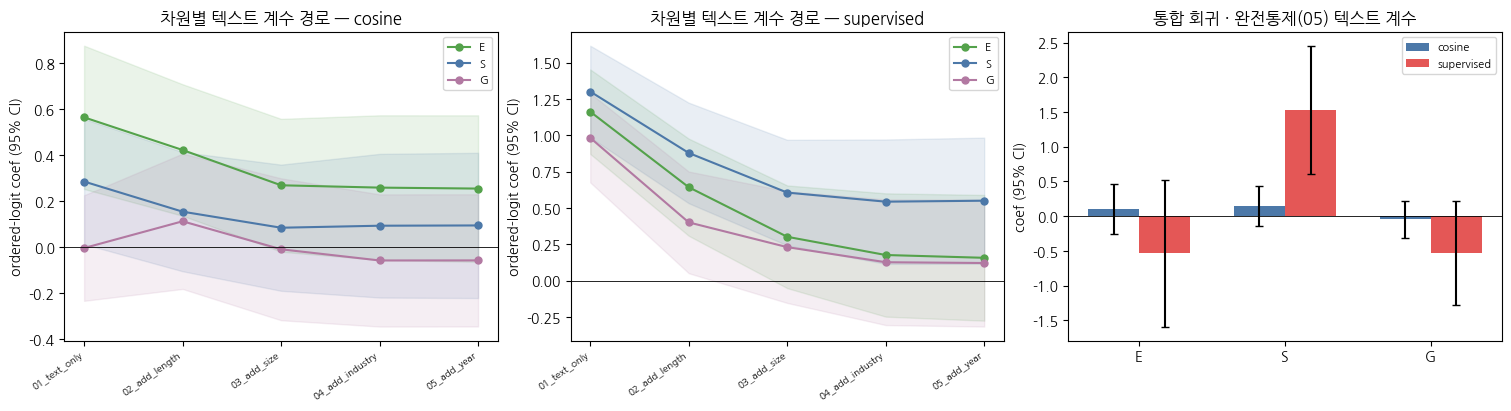


▶ [cosine] 차원별 텍스트효과 (전 스펙):
dimension            spec   coef  std_err_clustered  p_value significance
        E    01_text_only  0.565              0.159    0.000          ***
        E   02_add_length  0.423              0.146    0.004           **
        E     03_add_size  0.269              0.147    0.068             
        E 04_add_industry  0.259              0.161    0.107             
        E     05_add_year  0.255              0.163    0.117             
        S    01_text_only  0.285              0.139    0.040            *
        S   02_add_length  0.154              0.132    0.244             
        S     03_add_size  0.084              0.140    0.547             
        S 04_add_industry  0.093              0.159    0.560             
        S     05_add_year  0.094              0.161    0.559             
        G    01_text_only -0.004              0.117    0.972             
        G   02_add_length  0.112              0.150    0.454             
        

In [16]:
# ── Step 11.1 · 순서형 로짓: 차원별+통합 × {cosine,supervised}, 단계적 통제, 기업 cluster SE ──
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import warnings; warnings.filterwarnings("ignore")

_zf = lambda s: s.astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(6)
try:
    A
except NameError:
    A = pd.read_csv(DATA / "07_v2_analysis_table.csv", dtype={"stock_code": "string"})
    A["stock_code"] = _zf(A["stock_code"]); A["fiscal_year"] = A["fiscal_year"].astype(int)

sector_cols = sorted(c for c in A.columns if c.startswith("sector_"))
year_cols   = sorted(c for c in A.columns if c.startswith("year_"))
GROUPS = A["stock_code"].values; NC = len(set(GROUPS))
SPECS = [("01_text_only", []), ("02_add_length", ["log_core_doc_len_z"]),
         ("03_add_size", ["log_core_doc_len_z", "log_assets_z"]),
         ("04_add_industry", ["log_core_doc_len_z", "log_assets_z"] + sector_cols),
         ("05_add_year", ["log_core_doc_len_z", "log_assets_z"] + sector_cols + year_cols)]
TT = {"log_core_doc_len_z": "length", "log_assets_z": "size",
      **{c: "industry" for c in sector_cols}, **{c: "year" for c in year_cols}}
stars = lambda p: "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else np.nan
DIMS = ["E", "S", "G"]; GD = {"E": "e_grade", "S": "s_grade", "G": "g_grade"}

def _fit(y, xcols):
    r = OrderedModel(y, A[xcols].astype(float), distr="logit").fit(
        method="bfgs", disp=False, cov_type="cluster", cov_kwds={"groups": GROUPS})
    return r, r.conf_int()

def _vif(cols):
    X = sm.add_constant(A[cols].astype(float), has_constant="add")
    return {c: variance_inflation_factor(X.values, i + 1) for i, c in enumerate(cols)}

def run_matched(kind):                                       # kind: 'cos' | 'sup'
    S, V = [], []
    for d in DIMS:
        dv, txt = GD[d], f"{d}_{kind}_z"
        for spec, ctrl in SPECS:
            xcols = [txt] + ctrl; r, ci = _fit(A[dv], xcols)
            for t in xcols:
                p = float(r.pvalues[t])
                S.append(dict(dimension=d, target_grade_num=dv, spec=spec, term=t,
                              term_type="text_score" if t == txt else TT[t],
                              coef=float(r.params[t]), std_err_clustered=float(r.bse[t]), p_value=p,
                              aic=float(r.aic), n_obs=int(r.nobs), n_clusters=NC,
                              ci_low=float(ci.loc[t, 0]), ci_high=float(ci.loc[t, 1]), significance=stars(p)))
            for t, v in _vif(xcols).items():
                V.append(dict(dimension=d, spec=spec, term=t, vif=float(v)))
    return pd.DataFrame(S), pd.DataFrame(V)

def run_integrated(kind):
    txts = [f"{d}_{kind}_z" for d in DIMS]; S, V = [], []
    for spec, ctrl in SPECS:
        xcols = txts + ctrl; r, ci = _fit(A["esg_grade_num"], xcols)
        for t in xcols:
            p = float(r.pvalues[t])
            S.append(dict(spec=spec, target_grade_num="esg_grade_num", term=t,
                          term_type="text_score" if t in txts else TT[t],
                          coef=float(r.params[t]), std_err_clustered=float(r.bse[t]), p_value=p,
                          aic=float(r.aic), n_obs=int(r.nobs), n_clusters=NC,
                          ci_low=float(ci.loc[t, 0]), ci_high=float(ci.loc[t, 1]), significance=stars(p)))
        for t, v in _vif(xcols).items():
            V.append(dict(dimension="Integrated ESG", spec=spec, term=t, vif=float(v)))
    return pd.DataFrame(S), pd.DataFrame(V)

RES = {}
for kind, label in [("cos", "cosine"), ("sup", "supervised")]:
    msum, mvif = run_matched(kind); isum, ivif = run_integrated(kind)
    pre = f"07_v2_dense_{label}"
    msum.to_csv(DATA / f"{pre}_matched_ordered_logit_summary.csv", index=False)
    msum[msum.term_type == "text_score"].to_csv(DATA / f"{pre}_matched_ordered_logit_text_effects.csv", index=False)
    mvif.to_csv(DATA / f"{pre}_matched_ordered_logit_vif.csv", index=False)
    isum.to_csv(DATA / f"{pre}_integrated_ordered_logit_summary.csv", index=False)
    ivif.to_csv(DATA / f"{pre}_integrated_ordered_logit_vif.csv", index=False)
    RES[label] = dict(m=msum, i=isum)
    print(f"저장: {pre}_*  (matched {msum.shape}, integrated {isum.shape})")

# ── ① 시각화: 텍스트 계수 경로(단계적 통제) — 차원별 cosine·supervised + 통합 full-spec 비교 ──
SPEC_ORDER = [s for s, _ in SPECS]; xi = np.arange(len(SPEC_ORDER))
COL = {"E": "#54A24B", "S": "#4C78A8", "G": "#B279A2"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for k, (label, axk) in enumerate(zip(["cosine", "supervised"], ax[:2])):
    te = RES[label]["m"]; te = te[te.term_type == "text_score"]
    for d in DIMS:
        sub = te[te.dimension == d].set_index("spec").loc[SPEC_ORDER]
        axk.plot(xi, sub["coef"], "-o", color=COL[d], label=d, ms=5)
        axk.fill_between(xi, sub["ci_low"], sub["ci_high"], color=COL[d], alpha=.12)
    axk.axhline(0, color="k", lw=.6); axk.set_xticks(xi); axk.set_xticklabels(SPEC_ORDER, rotation=35, ha="right", fontsize=7)
    axk.set_title(f"차원별 텍스트 계수 경로 — {label}"); axk.set_ylabel("ordered-logit coef (95% CI)"); axk.legend(fontsize=8)
# 통합 full-spec(05_add_year) 텍스트 계수: cosine vs supervised
w = .35; xb = np.arange(3)
for j, label in enumerate(["cosine", "supervised"]):
    full = RES[label]["i"]; full = full[(full.spec == "05_add_year") & (full.term_type == "text_score")].set_index("term")
    cf = [full.loc[f"{d}_{'cos' if label=='cosine' else 'sup'}_z", "coef"] for d in DIMS]
    lo = [full.loc[f"{d}_{'cos' if label=='cosine' else 'sup'}_z", "ci_low"] for d in DIMS]
    hi = [full.loc[f"{d}_{'cos' if label=='cosine' else 'sup'}_z", "ci_high"] for d in DIMS]
    ax[2].bar(xb + (j - .5) * w, cf, w, label=label, color=["#4C78A8", "#E45756"][j],
              yerr=[np.array(cf) - lo, np.array(hi) - cf], capsize=3)
ax[2].axhline(0, color="k", lw=.6); ax[2].set_xticks(xb); ax[2].set_xticklabels(DIMS)
ax[2].set_title("통합 회귀 · 완전통제(05) 텍스트 계수"); ax[2].set_ylabel("coef (95% CI)"); ax[2].legend(fontsize=8)
plt.show()

# ── ② 샘플: 완전통제(05_add_year) 텍스트 효과 — cosine 차원별 + 통합 ──
def _show(df, cols):
    d = df.copy(); d["significance"] = d["significance"].fillna("")
    return d[cols].round(3).to_string(index=False)
print("\n▶ [cosine] 차원별 텍스트효과 (전 스펙):")
print(_show(RES["cosine"]["m"][RES["cosine"]["m"].term_type == "text_score"],
            ["dimension", "spec", "coef", "std_err_clustered", "p_value", "significance"]))
print("\n▶ [cosine] 통합 회귀 완전통제(05_add_year):")
print(_show(RES["cosine"]["i"][(RES["cosine"]["i"].spec == "05_add_year")],
            ["term", "term_type", "coef", "std_err_clustered", "p_value", "significance"]))

# ── ③ 해석 가이드 + 🚦 판정(생존 차원 요약) ──
def survivors(label, kind):
    te = RES[label]["m"]; full = te[(te.spec == "05_add_year") & (te.term_type == "text_score")]
    return [r["dimension"] for _, r in full.iterrows() if r["p_value"] < .05]
print("\n[해석 가이드]")
print(" • 'coef 경로'가 통제 추가(특히 02_length·03_size)에서 0 으로 주저앉으면 그 차원 신호는 분량/규모 교란이었다는 뜻.")
print(" • 완전통제(05_add_year)에서 p<.05 로 남는 텍스트 차원 = '분량·규모·업종·연도를 빼고도 등급과 연관'.")
print(" • supervised 는 누수(.6)가 커 01_text_only 가 과대 → 02 이후만 신뢰. cosine 과 생존차원 비교가 핵심.")
print(f"\n🚦 Step 11.1 (순서형 회귀): 완전통제 후 생존(p<.05) — cosine matched {survivors('cosine','cos')} | supervised matched {survivors('supervised','sup')}")
print("   ▶ 3트랙 대조: seed TF-IDF=G(.38**) / fastText 확장=없음 / dense=? (위 출력으로 확정). 다음=11.2 이진·OLS 강건성 + 통합 PCA(P5).")

## Step 11.2 — 강건성(이진 로짓·OLS) + 통합 PCA 합성요인(P5) 〔Colab · §6.2 · §6.5〕

> **이진·OLS**: 순서형 결론(완전통제 후 텍스트 생존 여부)이 링크함수에 강건한지 — `high_esg`(≥A)·`high_{dim}` 이진 로짓 + OLS(benchmark), 완전통제(`05_add_year`) 스펙, matched+integrated × {cosine·supervised}, 동일 기업 cluster SE.
> **PCA 합성요인(P5)**: 통합모형에서 E/S/G 텍스트가 공선(특히 supervised E_sup VIF 9.68 → 부호 뒤집힘)이라 개별계수 해석 불가 → `E/S/G_{kind}_z` 의 **PC1(공시품질 단일요인)** 하나로 축약해 순서형 적합(공선성 안전). Step 8 상한이 세 차원 비슷(단일요인)이었던 것과 정합.
> **선행**: Step 11.1 까지 실행돼 `A`·`RES`·`_fit`·`_vif`·`SPECS`·`GD` 등이 메모리에 있어야 함.

저장: 07_v2_dense_robustness_binary_ols.csv ·  07_v2_dense_integrated_pca_ordered_logit.csv


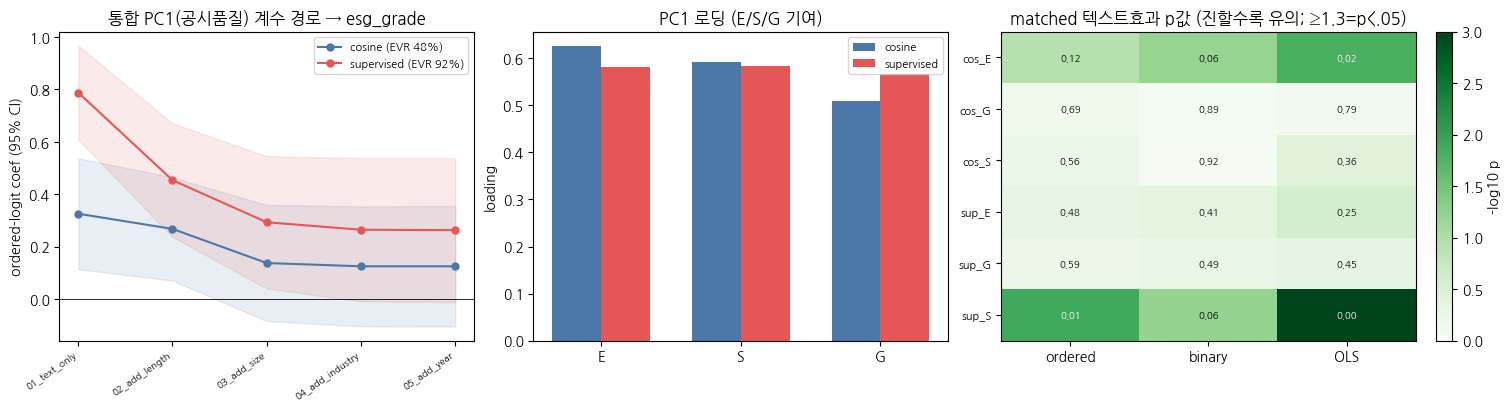


▶ 강건성 — matched 텍스트효과 (ordered vs binary vs OLS, 완전통제):
      kind dim   model   coef  p_value significance  odds_ratio
    cosine   E ordered  0.255    0.117                      NaN
    cosine   E  binary  0.366    0.062                    1.442
    cosine   E     OLS  0.232    0.015            *         NaN
    cosine   S ordered  0.094    0.559                      NaN
    cosine   S  binary  0.021    0.918                    1.021
    cosine   S     OLS  0.101    0.363                      NaN
    cosine   G ordered -0.058    0.693                      NaN
    cosine   G  binary -0.026    0.889                    0.974
    cosine   G     OLS -0.022    0.790                      NaN
supervised   E ordered  0.157    0.477                      NaN
supervised   E  binary  0.227    0.411                    1.255
supervised   E     OLS  0.165    0.253                      NaN
supervised   S ordered  0.550    0.013            *         NaN
supervised   S  binary  0.518    0.059         

In [17]:
# ── Step 11.2 · 강건성(이진·OLS) + 통합 PCA 합성요인(P5) ───────────────────────────
from sklearn.decomposition import PCA
try:
    A; RES; _fit; _vif; SPECS; GD; GROUPS; DIMS; stars; sector_cols; year_cols
except NameError:
    raise RuntimeError("Step 11.1 까지 위→아래 실행 필요 (A·RES·_fit·SPECS 등 메모리).")

FULL = ["log_core_doc_len_z", "log_assets_z"] + sector_cols + year_cols   # 완전통제(05_add_year)
for d in DIMS:
    A[f"high_{d}"] = (A[GD[d]] >= 4).astype(int)                          # 차원별 상위(A 이상)

def fit_logit(y, xcols):
    return sm.Logit(y, sm.add_constant(A[xcols].astype(float), has_constant="add")).fit(
        disp=False, cov_type="cluster", cov_kwds={"groups": GROUPS})
def fit_ols(y, xcols):
    return sm.OLS(y, sm.add_constant(A[xcols].astype(float), has_constant="add")).fit(
        cov_type="cluster", cov_kwds={"groups": GROUPS})

# ── (A) 강건성: 완전통제 텍스트효과를 ordered / binary / OLS 로 나란히 ──
rob = []
for kind, label in [("cos", "cosine"), ("sup", "supervised")]:
    for d in DIMS:                                                        # matched
        txt = f"{d}_{kind}_z"
        o = RES[label]["m"]; o = o[(o.dimension == d) & (o.spec == "05_add_year") & (o.term == txt)].iloc[0]
        rob.append(("matched", label, d, "ordered", o.coef, o.std_err_clustered, o.p_value, np.nan))
        rb = fit_logit(A[f"high_{d}"], [txt] + FULL)
        rob.append(("matched", label, d, "binary", rb.params[txt], rb.bse[txt], rb.pvalues[txt], np.exp(rb.params[txt])))
        ro = fit_ols(A[GD[d]], [txt] + FULL)
        rob.append(("matched", label, d, "OLS", ro.params[txt], ro.bse[txt], ro.pvalues[txt], np.nan))
    txts = [f"{d}_{kind}_z" for d in DIMS]                                # integrated
    oi = RES[label]["i"]; oi = oi[(oi.spec == "05_add_year") & (oi.term_type == "text_score")]
    for _, r in oi.iterrows():
        rob.append(("integrated", label, r.term.split("_")[0], "ordered", r.coef, r.std_err_clustered, r.p_value, np.nan))
    rb = fit_logit(A["high_esg"], txts + FULL); ro = fit_ols(A["esg_grade_num"], txts + FULL)
    for t in txts:
        rob.append(("integrated", label, t.split("_")[0], "binary", rb.params[t], rb.bse[t], rb.pvalues[t], np.exp(rb.params[t])))
        rob.append(("integrated", label, t.split("_")[0], "OLS", ro.params[t], ro.bse[t], ro.pvalues[t], np.nan))
rob = pd.DataFrame(rob, columns=["scope", "kind", "dim", "model", "coef", "se", "p_value", "odds_ratio"])
rob["significance"] = rob["p_value"].apply(stars)
rob.to_csv(DATA / "07_v2_dense_robustness_binary_ols.csv", index=False)

# ── (B) 통합 PCA 합성요인: E/S/G_{kind}_z → PC1 → 순서형(단계적) ──
pca_rows, load_rows = [], []
for kind, label in [("cos", "cosine"), ("sup", "supervised")]:
    cols = [f"{d}_{kind}_z" for d in DIMS]
    pc = PCA(n_components=1, random_state=0).fit(A[cols])
    comp = pc.components_[0].copy(); score = pc.transform(A[cols])[:, 0]
    if comp.sum() < 0: comp, score = -comp, -score                       # 양의 방향(공시품질↑) 정렬
    A[f"PC1_{kind}"] = score; ev = float(pc.explained_variance_ratio_[0])
    for d, w in zip(DIMS, comp): load_rows.append((label, d, float(w)))
    for spec, ctrl in SPECS:
        xcols = [f"PC1_{kind}"] + ctrl; r, _ = _fit(A["esg_grade_num"], xcols)
        p = float(r.pvalues[f"PC1_{kind}"])
        pca_rows.append(dict(kind=label, spec=spec, evr=ev, coef=float(r.params[f"PC1_{kind}"]),
                             se=float(r.bse[f"PC1_{kind}"]), p_value=p, significance=stars(p),
                             vif_max=float(max(_vif(xcols).values()))))
pca = pd.DataFrame(pca_rows); loads = pd.DataFrame(load_rows, columns=["kind", "dim", "loading"])
pca.to_csv(DATA / "07_v2_dense_integrated_pca_ordered_logit.csv", index=False)
print("저장: 07_v2_dense_robustness_binary_ols.csv ·  07_v2_dense_integrated_pca_ordered_logit.csv")

# ── ① 시각화: PC1 생존경로 · PCA 로딩 · 강건성(matched -log10 p) ──
SPEC_ORDER = [s for s, _ in SPECS]; xi = np.arange(len(SPEC_ORDER))
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for label, c in [("cosine", "#4C78A8"), ("supervised", "#E45756")]:
    sub = pca[pca.kind == label].set_index("spec").loc[SPEC_ORDER]
    ax[0].plot(xi, sub["coef"], "-o", color=c, label=f"{label} (EVR {sub['evr'].iloc[0]:.0%})", ms=5)
    ax[0].fill_between(xi, sub["coef"] - 1.96 * sub["se"], sub["coef"] + 1.96 * sub["se"], color=c, alpha=.12)
ax[0].axhline(0, color="k", lw=.6); ax[0].set_xticks(xi); ax[0].set_xticklabels(SPEC_ORDER, rotation=35, ha="right", fontsize=7)
ax[0].set_title("통합 PC1(공시품질) 계수 경로 → esg_grade"); ax[0].set_ylabel("ordered-logit coef (95% CI)"); ax[0].legend(fontsize=8)
w = .35; xb = np.arange(3)
for j, label in enumerate(["cosine", "supervised"]):
    ax[1].bar(xb + (j - .5) * w, loads[loads.kind == label].set_index("dim").loc[DIMS, "loading"], w,
              label=label, color=["#4C78A8", "#E45756"][j])
ax[1].axhline(0, color="k", lw=.6); ax[1].set_xticks(xb); ax[1].set_xticklabels(DIMS)
ax[1].set_title("PC1 로딩 (E/S/G 기여)"); ax[1].set_ylabel("loading"); ax[1].legend(fontsize=8)
piv = rob[rob.scope == "matched"].copy(); piv["row"] = piv["kind"].str[:3] + "_" + piv["dim"]
M = piv.pivot_table(index="row", columns="model", values="p_value").reindex(columns=["ordered", "binary", "OLS"])
L = -np.log10(M.values); im = ax[2].imshow(L, cmap="Greens", vmin=0, vmax=3, aspect="auto")
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(["ordered", "binary", "OLS"]); ax[2].set_yticks(range(len(M))); ax[2].set_yticklabels(M.index, fontsize=8)
for i in range(len(M)):
    for j in range(3):
        ax[2].text(j, i, f"{M.values[i,j]:.2f}", ha="center", va="center", fontsize=7,
                   color="white" if L[i, j] > 1.3 else "black")
ax[2].set_title("matched 텍스트효과 p값 (진할수록 유의; ≥1.3=p<.05)"); fig.colorbar(im, ax=ax[2], fraction=.046, label="-log10 p")
plt.show()

# ── ② 샘플: 강건성 표(matched) + PC1 완전통제 + 로딩 ──
print("\n▶ 강건성 — matched 텍스트효과 (ordered vs binary vs OLS, 완전통제):")
sh = rob[rob.scope == "matched"].copy(); sh["significance"] = sh["significance"].fillna("")
print(sh[["kind", "dim", "model", "coef", "p_value", "significance", "odds_ratio"]].round(3).to_string(index=False))
print("\n▶ 통합 PC1 완전통제(05_add_year) + 로딩:")
print(pca[pca.spec == "05_add_year"][["kind", "evr", "coef", "se", "p_value", "significance", "vif_max"]].round(3).to_string(index=False))
print(loads.pivot(index="kind", columns="dim", values="loading").round(3).to_string())

# ── ③ 해석 + 🚦 판정 ──
pc1_surv = pca[(pca.spec == "05_add_year") & (pca.p_value < .05)]["kind"].tolist()
print("\n[해석 가이드]")
print(" • 강건성: 순서형에서 비유의였던 차원이 binary·OLS 에서도 비유의면 '결론이 링크함수에 강건'(우연 아님).")
print(" • PC1: 통합서 개별 E/S/G 계수가 공선으로 못 믿을 때, 단일 공시품질요인(PC1)이 등급과 연관되는지로 대체 판단.")
print(" • PC1 VIF<2(설계상 1개 텍스트항) → 통합 supervised 부호뒤집힘 문제 해소. PC1 도 완전통제서 죽으면 '통합 텍스트신호도 분량·규모'.")
print(f"\n🚦 Step 11.2: PC1 완전통제 생존(p<.05) = {pc1_surv if pc1_surv else '없음'} | matched 강건성 표 위 참조.")
print("   ▶ 다음: Step 12 보고서 — 3트랙 종합표(seed=G / 확장=없음 / dense cosine=없음·sup=S) + 한계(`06_outputs_limits.md`).")

## Step 12 — 최종 보고서 (Markdown + HTML) + outputs.zip 〔Colab · §9 · §10〕

> 저장된 회귀 산출물(`07_v2_dense_*`)에서 **3트랙 종합표**와 최종 보고서를 조립한다. 서술 순서 = 실패진단 → 개선근거 → 결과(게이트) → 회귀 → 한계. 산출 = `outputs/`(`synthesis_3track.csv`·`regression_results.csv`·`final_report.md`·`final_report.html`·`outputs.zip`).
> **선행**: 11.2 까지 실행돼 `A`·`DATA`·`PROJECT` 와 `07_v2_dense_robustness_binary_ols.csv`·`..._integrated_pca_ordered_logit.csv` 존재.

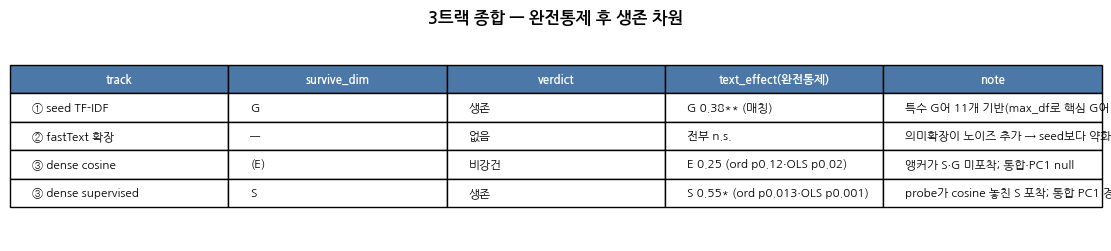

▶ outputs/ 산출물:
   final_report.html                 5,523B
   final_report.md                   4,406B
   outputs.zip                     102,660B
   pca_results.csv                   1,225B
   regression_results.csv            3,375B
   synthesis_3track.csv                478B

▶ final_report.md (앞부분):
# Dense ESG v2 — 최종 분석 보고서
작성일 2026-06-01 · 코드 `notebooks/07b_dense_esg_v2_colab.ipynb` · 표본 127사×3년=381 기업-연도

## 0. 핵심 메시지
한국 상장사 사업보고서(II·IV·VI) ESG 서술과 KCGS ESG 등급의 연관은 **대부분 "공시 분량"(규모·자원의 대리)에서 온다.** 등급↔분량 순위상관 ρ≈0.58~0.63. **분량·규모·업종·연도를 모두 통제하면 텍스트–등급 연관은 약~null** 로 줄고, 표현 방식마다 **다른 차원**이 약하게 떠오른다(seed TF-IDF=G, dense cosine=E(비강건), dense supervised=S). 모든 모델에서 **규모(log 총자산)가 1차 지배 예측자**다. → "공시가 등급을 만든다"는 인과 주장 불가; 약한 연관·강한 분량/규모 교란.

방법론 기여: **임베딩 화이트닝(ABTT) + 하위차원 앵커 + 길이강건 풀링** 이 단순 cosine의 분량 누수(.46~.66→.25 이하)와 차원 간 공선성(0.84→0.48)을 실제로 크게 줄였다.

## 1. 게이트 결과 요약
- **G1 전처리** PASS — 표/거대문장 붕괴 교정(최장 222,465자→1,000, 총문장 +58%).
- **G2 분량누수** PASS — 채택 풀링(softmax0.05) cosine 누수 

In [19]:
# ── Step 12 · 최종 보고서 + outputs.zip ───────────────────────────────────────────
import zipfile, datetime
OUT = PROJECT / "outputs"; OUT.mkdir(exist_ok=True)
rob = pd.read_csv(DATA / "07_v2_dense_robustness_binary_ols.csv")
pca = pd.read_csv(DATA / "07_v2_dense_integrated_pca_ordered_logit.csv")

def _g(scope, kind, dim, model, col):
    r = rob[(rob.scope == scope) & (rob.kind == kind) & (rob.dim == dim) & (rob.model == model)]
    return float(r[col].iloc[0])
V = dict(
    date=str(datetime.date.today()),
    cosE=_g("matched", "cosine", "E", "ordered", "coef"), cosE_p=_g("matched", "cosine", "E", "ordered", "p_value"),
    cosE_olsp=_g("matched", "cosine", "E", "OLS", "p_value"),
    supS=_g("matched", "supervised", "S", "ordered", "coef"), supS_p=_g("matched", "supervised", "S", "ordered", "p_value"),
    supS_olsp=_g("matched", "supervised", "S", "OLS", "p_value"),
)
pc = pca[pca.spec == "05_add_year"].set_index("kind")
V.update(cosPC_p=float(pc.loc["cosine", "p_value"]), supPC_p=float(pc.loc["supervised", "p_value"]),
         supPC_evr=float(pc.loc["supervised", "evr"]))

# ── 3트랙 종합표 (dense=CSV에서, seed/확장=문서화 상수) ──
synth = pd.DataFrame([
    ("① seed TF-IDF",      "G",   "생존",   "G 0.38** (매칭)",                              "특수 G어 11개 기반(max_df로 핵심 G어 일부 제거)"),
    ("② fastText 확장",     "—",   "없음",   "전부 n.s.",                                    "의미확장이 노이즈 추가 → seed보다 약화"),
    ("③ dense cosine",     "(E)", "비강건", f"E {V['cosE']:.2f} (ord p{V['cosE_p']:.2f}·OLS p{V['cosE_olsp']:.2f})", "앵커가 S·G 미포착; 통합·PC1 null"),
    ("③ dense supervised", "S",   "생존",   f"S {V['supS']:.2f}* (ord p{V['supS_p']:.3f}·OLS p{V['supS_olsp']:.3f})", "probe가 cosine 놓친 S 포착; 통합 PC1 경계"),
], columns=["track", "survive_dim", "verdict", "text_effect(완전통제)", "note"])
synth.to_csv(OUT / "synthesis_3track.csv", index=False)
rob.to_csv(OUT / "regression_results.csv", index=False)
pca.to_csv(OUT / "pca_results.csv", index=False)

# ── 최종 보고서 (Markdown) ──
TEMPLATE = r"""# Dense ESG v2 — 최종 분석 보고서
작성일 {date} · 코드 `notebooks/07b_dense_esg_v2_colab.ipynb` · 표본 127사×3년=381 기업-연도

## 0. 핵심 메시지
한국 상장사 사업보고서(II·IV·VI) ESG 서술과 KCGS ESG 등급의 연관은 **대부분 "공시 분량"(규모·자원의 대리)에서 온다.** 등급↔분량 순위상관 ρ≈0.58~0.63. **분량·규모·업종·연도를 모두 통제하면 텍스트–등급 연관은 약~null** 로 줄고, 표현 방식마다 **다른 차원**이 약하게 떠오른다(seed TF-IDF=G, dense cosine=E(비강건), dense supervised=S). 모든 모델에서 **규모(log 총자산)가 1차 지배 예측자**다. → "공시가 등급을 만든다"는 인과 주장 불가; 약한 연관·강한 분량/규모 교란.

방법론 기여: **임베딩 화이트닝(ABTT) + 하위차원 앵커 + 길이강건 풀링** 이 단순 cosine의 분량 누수(.46~.66→.25 이하)와 차원 간 공선성(0.84→0.48)을 실제로 크게 줄였다.

## 1. 게이트 결과 요약
- **G1 전처리** PASS — 표/거대문장 붕괴 교정(최장 222,465자→1,000, 총문장 +58%).
- **G2 분량누수** PASS — 채택 풀링(softmax0.05) cosine 누수 E .29/S .26/G −.09 (≪ 기존 .61/.66/.46).
- **G3 판별타당도** FAIL(부분 대각지배 1/3=E만) — 단, 피처 공선성은 해결(E–S .844→.479). 단일요인.
- **G4 다중공선성** PASS — 완전모형 max VIF 4.9~9.7(<10). 규모↔분량 r=.76도 VIF~2.8.
- **G5 지도프로브** PASS — GroupKFold(기업) OOF만, 누설 assert 통과.

## 2. 핵심 발견
1. **분량이 지배 교란.** own-grade 신호의 대부분이 분량이며, 분량 통제 후 cosine 순수신호는 E~.17/S~.06/G~.03.
2. **지도 프로브 상한 > cosine.** probe OOF 부분ρ E .27/S .28/G .19 → 임베딩엔 verbosity 너머 신호가 있으나 cosine은 E만 포착(S·G 놓침). 상한이 세 차원 비슷 → 차원특정 아닌 **단일 공시품질 요인**.
3. **정식 회귀(기업 cluster SE)의 결론(아래 §3)** 은 부분상관보다 보수적: cosine E는 비강건, supervised S만 강건.

## 3. 회귀 결과 (순서형 로짓 · 단계적 통제 · 기업 cluster SE)
통제: `01_text_only → +길이(log core 문자수) → +규모(log 자산) → +업종 → +연도`. z-score, 기업 군집 SE.

- **dense cosine (차원별):** E {cosE:.3f} (ordered p{cosE_p:.3f}, OLS p{cosE_olsp:.3f}) — 규모 추가에서 유의성 상실, **링크함수 민감(OLS만 유의)=비강건**. S/G null.
- **dense supervised (차원별):** **S {supS:.3f}** (ordered p{supS_p:.3f}\*, OLS p{supS_olsp:.3f}\*\*) — **세 모델 일관 유의 = 덴스 유일 강건 신호.** E/G null.
- **통합 PC1(공시품질 단일요인):** cosine p{cosPC_p:.3f}(null) · supervised p{supPC_p:.3f}(경계, EVR {supPC_evr:.0%}) — 세 차원 균일 로딩 → 단일요인 확증. 통합 텍스트도 분량·규모로 대부분 설명.
- 모든 모형에서 **log 총자산 계수 최대(1.1~1.5\*\*\*)** = 규모 지배.

## 4. 3트랙 종합
{synth_table}

메타: 표현 방식마다 약한 신호가 **다른 차원**에서 잡히고(어느 것도 강하지 않음), 공통적으로 **규모·분량이 1차 교란**. seed TF-IDF의 G 생존은 특수 G어 기반, dense supervised의 S 생존은 probe가 cosine·앵커의 사각을 메운 결과.

## 5. 한계
- 화이트닝은 이방성 완화일 뿐 완전 제거 아님 → 순위·상관 위주 해석.
- cosine은 ESG 원형 **근접도**이지 실제 성과·진정성 아님(그린워싱 구분 불가).
- 7단계 순서형 등급은 거친 종속변수; 3년 패널·기업당 변동 작음(within 신호 약함).
- 지도 프로브 상한은 구성상 낙관(중첩 CV가 줄이나 제거 못 함) → "상한"으로만.
- 앵커는 연구자 정의(구성타당도 전제) · 업종/규모 통제 품질에 결과 좌우.
"""
synth_md = "| " + " | ".join(synth.columns) + " |\n| " + " | ".join(["---"] * len(synth.columns)) + " |\n" + \
           "\n".join("| " + " | ".join(str(x) for x in r) + " |" for r in synth.values)
report_md = TEMPLATE.format(synth_table=synth_md, **V)
(OUT / "final_report.md").write_text(report_md, encoding="utf-8")

# ── HTML (markdown 패키지 있으면 변환, 없으면 <pre> 폴백) ──
try:
    import markdown as _mdlib
    body = _mdlib.markdown(report_md, extensions=["tables"])
except Exception:
    body = "<pre>" + report_md.replace("<", "&lt;") + "</pre>"
html = ("<html><head><meta charset='utf-8'><style>body{font-family:-apple-system,sans-serif;"
        "max-width:920px;margin:2em auto;line-height:1.6;color:#222}table{border-collapse:collapse;margin:1em 0}"
        "td,th{border:1px solid #ccc;padding:4px 9px;font-size:.93em}h1,h2{border-bottom:1px solid #eee}</style>"
        "</head><body>" + body + "</body></html>")
(OUT / "final_report.html").write_text(html, encoding="utf-8")

# ── outputs.zip ──
zip_path = OUT / "outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.glob("*.csv"): z.write(p, p.name)
    for p in OUT.glob("final_report.*"): z.write(p, p.name)
    z.write(DATA / "07_v2_analysis_table.csv", "data/07_v2_analysis_table.csv")
    for p in sorted(DATA.glob("07_v2_dense_*.csv")): z.write(p, "data/" + p.name)

# ── ① 시각화: 종합표 + 생존 요약 ──
fig, ax = plt.subplots(figsize=(11, 2.4), constrained_layout=True); ax.axis("off")
tb = ax.table(cellText=synth.values, colLabels=synth.columns, loc="center", cellLoc="left")
tb.auto_set_font_size(False); tb.set_fontsize(8.5); tb.scale(1, 1.5)
for j in range(len(synth.columns)): tb[0, j].set_facecolor("#4C78A8"); tb[0, j].set_text_props(color="white", fontweight="bold")
ax.set_title("3트랙 종합 — 완전통제 후 생존 차원", fontweight="bold"); plt.show()

# ── ② 샘플: 산출물 목록 + 보고서 머리 ──
print("▶ outputs/ 산출물:")
for p in sorted(OUT.glob("*")):
    print(f"   {p.name:30s} {p.stat().st_size:>8,}B")
print("\n▶ final_report.md (앞부분):"); print("\n".join(report_md.splitlines()[:14]))

# ── ③ 해석 + 🚦 파이프라인 완료 ──
print("\n[해석 가이드]")
print(" • synthesis_3track.csv = 논문/PPT 종합표 원본. regression_results.csv = 회귀 전체(ordered·binary·OLS), pca_results.csv = 통합 PC1.")
print(" • final_report.html 단일 파일로 공유 가능. outputs.zip = 보고서+표+분석테이블+회귀결과 일괄.")
print("\n🚦 Step 12 (보고서): 생성 완료 ✅ — 3트랙 종합표·final_report.(md|html)·outputs.zip.")
print("   ▶ Dense ESG v2 파이프라인(Step 1~12) 종료. dense_기록.md 에 §3 정정 회귀결과 반영 권장.")